# Lab 9 – Modern NLP Final Project Development
**Học phần:** Xử lý Ngôn ngữ Tự nhiên (1230554) · **Dự án:** SSA-VN – Trợ lý hỗ trợ sinh viên bằng tiếng Việt

| | |
|---|---|
| **Họ tên** | Nguyễn Hoàng Phúc |
| **MSSV** | 24DH190314 |
| **Hình thức** | Cá nhân (không làm nhóm) |

**Pipeline:** phân loại chủ đề → truy hồi (BM25 / dense / hybrid) → RAG có từ chối → đánh giá, ablation, phân tích lỗi.

**Cách chạy:** đặt notebook cùng thư mục với `student_pack_24DH190314/` (và `lab9_tools.py` nếu có), chọn *Restart & Run All*.
Phần bắt buộc (BB) chạy được trên CPU; phần LoRA (C4, NC) tự bật khi có GPU. Cell D1 cần tải LLM nhỏ từ Hugging Face.

**Mục lục:** A (dữ liệu) · B (baseline cổ điển) · C (embedding, dense, hybrid, LoRA) · D (LLM, RAG, từ chối) · E (tính tay LoRA/DPO/metric) · F (ablation, lỗi, dữ liệu tự tạo) · Kết quả & báo cáo.

In [1]:
# !pip -q install pandas scikit-learn sentence-transformers peft transformers pyvi

In [2]:
import json, math, re, pathlib, unicodedata, time, random, os, warnings
import numpy as np, pandas as pd
from collections import Counter, defaultdict
warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120, "display.width", 200)

MSSV = "24DH190314"
PACK = pathlib.Path(f"student_pack_{MSSV}")        # tạo bằng: python lab9_tools.py pack --mssv <MSSV>
card = json.load(open(PACK / "personal_card.json", encoding="utf-8"))
SEED = card["seed"]
random.seed(SEED); np.random.seed(SEED)

try:                                               # torch chỉ cần cho LoRA và LLM
    import torch
    torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    torch, DEVICE = None, "cpu"

print("MSSV:", card["mssv"], "| seed:", SEED, "| device:", DEVICE)
print("check_code:", card["check_code"], "| noise:", card["noise"], "| topic_pair:", card["topic_pair"])
print("embed_model:", card["embed_model"], "| clf_backbone:", card["clf_backbone"])
print("lora:", card["lora"], "| fewshot_k:", card["fewshot_k"], "| rag_top_k:", card["rag_top_k"], "| ablation:", card["ablation"])

# Đối chiếu thẻ với công cụ của giảng viên (nếu có lab9_tools.py cạnh notebook)
try:
    from lab9_tools import assign
    assert assign(MSSV)["check_code"] == card["check_code"], "Thẻ không khớp MSSV!"
    print("✔ check_code khớp với lab9_tools.assign(MSSV)")
except ImportError:
    print("(không có lab9_tools.py – bỏ qua đối chiếu)")

MSSV: 24DH190314 | seed: 58202 | device: cpu
check_code: 927D30B4 | noise: code_mix | topic_pair: ['thi_diem', 'thu_vien_cntt']
embed_model: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2 | clf_backbone: xlm-roberta-base
lora: {'r': 8, 'alpha': 16, 'dropout': 0.1, 'target_modules': ['query', 'value']} | fewshot_k: 6 | rag_top_k: 2 | ablation: A4
✔ check_code khớp với lab9_tools.assign(MSSV)


## Phần A – Dữ liệu & tiền xử lý
### A1. Nạp dữ liệu, phân bố nhãn, độ dài câu, câu clean vs noisy

In [3]:
rd = lambda f: pd.read_csv(PACK / f)
kb, tr, te, te_noisy = rd("kb_passages.csv"), rd("clf_train.csv"), rd("clf_test.csv"), rd("clf_test_noisy.csv")
dev, rq, rq_noisy = rd("retr_dev.csv"), rd("retr_test.csv"), rd("retr_test_noisy.csv")
fewshot, llm_eval, ood = rd("fewshot_pool.csv"), rd("llm_eval_30.csv"), rd("ood_10.csv")
print("train", tr.shape, "| test", te.shape, "| test_noisy", te_noisy.shape, "| kb", kb.shape)
print("dev", dev.shape, "| retr_test", rq.shape, "| retr_test_noisy", rq_noisy.shape)

TOPICS = sorted(tr.topic.unique())                 # 8 chủ đề
print("\nPhân bố nhãn (số câu hỏi):")
print(pd.DataFrame({"train": tr.topic.value_counts(), "test": te.topic.value_counts()}).fillna(0).astype(int))

# độ dài câu trung bình (tính theo âm tiết = số từ tách bằng khoảng trắng)
for name, df in [("train", tr), ("test", te), ("test_noisy", te_noisy)]:
    print(f"{name:11s}: {df.text.str.split().str.len().mean():.2f} âm tiết/câu | {df.text.str.len().mean():.1f} ký tự/câu")

# 5 câu clean đặt cạnh 5 câu noisy (cùng qid) – chọn ngẫu nhiên trong các câu thực sự bị đổi
assert (te.qid.values == te_noisy.qid.values).all()
changed = np.where(te.text.values != te_noisy.text.values)[0]
print(f"\nNhiễu '{card['noise']}' làm thay đổi {len(changed)}/{len(te)} câu ({len(changed)/len(te):.1%}).")
pick = np.random.RandomState(SEED).choice(changed, 5, replace=False)
print(pd.DataFrame({"qid": te.qid.values[pick], "clean": te.text.values[pick], "noisy": te_noisy.text.values[pick]}).to_string(index=False))

train (1392, 8) | test (528, 8) | test_noisy (528, 8) | kb (80, 5)
dev (116, 8) | retr_test (132, 8) | retr_test_noisy (132, 8)

Phân bố nhãn (số câu hỏi):
                  train  test
topic                        
ctsv                168    72
dang_ky_hoc_phan    168    72
hoc_bong            168    72
hoc_phi             168    72
ky_tuc_xa           168    72
thi_diem            192    48
thu_vien_cntt       192    48
tot_nghiep          168    72
train      : 14.11 âm tiết/câu | 61.1 ký tự/câu
test       : 13.69 âm tiết/câu | 58.5 ký tự/câu
test_noisy : 13.20 âm tiết/câu | 59.4 ký tự/câu

Nhiễu 'code_mix' làm thay đổi 239/528 câu (45.3%).
    qid                                                                          clean                                                                                noisy
Q047-12               Có deadline cho việc nộp khóa luận tốt nghiệp không, là bao giờ?                  Có deadline cho việc submit khóa luận graduation không, là bao giờ?
Q078

**Nhận xét A1.** Tám chủ đề cân bằng ở mức mục (mỗi chủ đề 10 mục trong KB); số câu hỏi/chủ đề ở train–test lệch nhau chỉ vì mỗi mục sinh ~24 câu hỏi và số mục của từng chủ đề trong train/test khác nhau. Câu hỏi ngắn (khoảng 12–15 âm tiết). Nhiễu `code_mix` thay các từ khóa tiếng Việt thường gặp (*học phí → tuition, điểm → grade, đăng ký → register…*) bằng tiếng Anh, nên chỉ một phần câu bị đổi (xem tỉ lệ ở trên) và những câu đổi là những câu chứa đúng các từ khóa ấy.

### A2. Kiểm chứng không rò rỉ (tách theo **mục**, không tách theo câu)

In [4]:
# Kiểm tra bắt buộc: không item nào xuất hiện ở cả train và test
assert set(tr.item_id).isdisjoint(set(te.item_id)), "Rò rỉ dữ liệu: item trùng giữa train/test!"
assert set(dev.item_id) <= set(tr.item_id), "dev phải lấy từ mục train"
assert set(rq.item_id) <= set(te.item_id), "retr_test phải lấy từ mục test"
assert set(dev.item_id).isdisjoint(set(rq.item_id)), "Rò rỉ dev→test!"
assert set(fewshot.item_id).isdisjoint(set(te.item_id)), "few-shot pool không được chứa mục test"
print(f"✔ Không rò rỉ: train {tr.item_id.nunique()} mục, test {te.item_id.nunique()} mục, "
      f"mỗi mục có ~{len(tr)/tr.item_id.nunique():.0f} câu hỏi diễn đạt lại cùng một quy định.")

# Thí nghiệm: nếu tách ngẫu nhiên THEO CÂU thì kết quả "đẹp" giả vì đã thấy mục đó lúc train
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.model_selection import train_test_split

def normalize(s: str) -> str:
    s = unicodedata.normalize("NFC", str(s)).lower()
    s = re.sub(r"[^\w\s]", " ", s)          # bỏ dấu câu
    return re.sub(r"\s+", " ", s).strip()

def tok(s: str):                              # tách theo âm tiết (khoảng trắng)
    return normalize(s).split()

def tfidf_lr_acc(train_df, test_df):
    v = TfidfVectorizer(preprocessor=normalize, ngram_range=(1, 2), sublinear_tf=True)
    m = LogisticRegression(max_iter=2000, random_state=SEED).fit(v.fit_transform(train_df.text), train_df.topic)
    return accuracy_score(test_df.topic, m.predict(v.transform(test_df.text)))

all_q = pd.concat([tr, te], ignore_index=True)
a_row, b_row = train_test_split(all_q, test_size=len(te), stratify=all_q.topic, random_state=SEED)
print(f"Tách ngẫu nhiên THEO CÂU : acc = {tfidf_lr_acc(a_row, b_row):.3f}  (số mục trùng train/test: {len(set(a_row.item_id) & set(b_row.item_id))})")
print(f"Tách THEO MỤC (đề bài)   : acc = {tfidf_lr_acc(tr, te):.3f}  (số mục trùng train/test: 0)")

✔ Không rò rỉ: train 58 mục, test 22 mục, mỗi mục có ~24 câu hỏi diễn đạt lại cùng một quy định.
Tách ngẫu nhiên THEO CÂU : acc = 1.000  (số mục trùng train/test: 80)
Tách THEO MỤC (đề bài)   : acc = 0.653  (số mục trùng train/test: 0)


**Giải thích A2.** Mỗi *mục* (item) là một quy định; ~24 câu hỏi của cùng một mục chỉ là cách diễn đạt khác nhau của cùng nội dung (ten/alias, hỏi đơn vị/thời hạn/lệ phí). Nếu tách ngẫu nhiên theo câu, các câu "anh em" của một câu test nằm sẵn trong train, mô hình chỉ cần nhớ mục đó → accuracy phồng lên (xem thí nghiệm: tách theo câu cao hơn hẳn tách theo mục). Tách theo mục mới đo đúng khả năng **khái quát sang quy định chưa từng thấy**, giống tình huống triển khai thật. Vì vậy dev (từ mục train) và test (từ mục test) cũng tách theo mục.

### A3. Hàm `normalize` (NFC → lowercase → bỏ dấu câu → gọn khoảng trắng)

In [5]:
ex = te.text[te.text.str.contains(r"[A-ZĐ]") & te.text.str.contains(r"[,?]")].iloc[0]
print("Gốc          :", repr(ex))
print("split() thô  :", ex.split())
print("tok()        :", tok(ex))

nfd = unicodedata.normalize("NFD", ex)         # cùng chữ nhưng dấu tách rời (hay gặp khi copy từ Mac/PDF/Word)
print(f"\nNFD khác NFC? {nfd != ex} | độ dài: NFC={len(ex)}, NFD={len(nfd)} ký tự")
print("split() thô của NFD :", nfd.split()[:4], "…")
print("normalize(NFD) == normalize(NFC)?", normalize(nfd) == normalize(ex))

Gốc          : 'Muốn đăng ký học lại thì thực hiện ở đâu?'
split() thô  : ['Muốn', 'đăng', 'ký', 'học', 'lại', 'thì', 'thực', 'hiện', 'ở', 'đâu?']
tok()        : ['muốn', 'đăng', 'ký', 'học', 'lại', 'thì', 'thực', 'hiện', 'ở', 'đâu']

NFD khác NFC? True | độ dài: NFC=41, NFD=55 ký tự
split() thô của NFD : ['Muốn', 'đăng', 'ký', 'học'] …
normalize(NFD) == normalize(NFC)? True


**Giải thích A3.** (1) **NFC**: tiếng Việt có hai cách mã hóa cùng một chữ (ví dụ `ọ` là 1 ký tự hoặc `o` + dấu nặng rời). Hai chuỗi nhìn giống hệt nhưng so sánh bằng nhau là `False`, nên từ điển TF-IDF/BM25 coi là hai từ khác nhau; NFC đưa về một dạng. (2) **lowercase**: `Học` và `học` thành một từ. (3) **Bỏ dấu câu**: `phí?` và `phí,` không còn dính dấu vào từ → khớp được với `phí` trong đoạn quy định. (4) **Gọn khoảng trắng** để `split()` không sinh token rỗng. Hiệu quả định lượng trên truy hồi được đo ở cell *A3 (bổ sung)* ngay sau BM25.

## Phần B – Baseline cổ điển
### B1. TF-IDF + Logistic Regression (clean và noisy)

In [6]:
vec = TfidfVectorizer(preprocessor=normalize, ngram_range=(1, 2), sublinear_tf=True)
Xtr = vec.fit_transform(tr.text)
clf = LogisticRegression(max_iter=2000, random_state=SEED).fit(Xtr, tr.topic)
res = {}
for name, df in [("clean", te), ("noisy", te_noisy)]:
    pred = clf.predict(vec.transform(df.text))
    res[name] = {"acc": accuracy_score(df.topic, pred), "macro_f1": f1_score(df.topic, pred, average="macro")}
print(pd.DataFrame(res).T.round(4))
pred_tfidf = {"clean": clf.predict(vec.transform(te.text)), "noisy": clf.predict(vec.transform(te_noisy.text))}

          acc  macro_f1
clean  0.6534    0.6344
noisy  0.5076    0.4871


### B2. BM25 (cài đặt của giảng viên) + Recall@1/3/5/10, MRR@10, nDCG@10

In [7]:
class BM25:
    # (chỉ thêm tham số tokenizer, mặc định = tok, để cell A3-bổ sung so sánh được cách tách từ)
    def __init__(self, docs, k1=1.5, b=0.75, tokenizer=None):
        self.k1, self.b = k1, b
        self.tokenizer = tokenizer or tok
        self.tf = [Counter(self.tokenizer(d)) for d in docs]
        self.dl = np.array([sum(c.values()) for c in self.tf], dtype=float)
        self.avg = self.dl.mean()
        df = Counter(w for c in self.tf for w in c)
        n = len(docs)
        self.idf = {w: math.log(1 + (n - f + 0.5) / (f + 0.5)) for w, f in df.items()}

    def scores(self, q):
        s = np.zeros(len(self.tf))
        for w in self.tokenizer(q):
            if w not in self.idf:
                continue
            for i, c in enumerate(self.tf):
                f = c.get(w, 0)
                if f:
                    s[i] += self.idf[w] * f * (self.k1 + 1) / (f + self.k1 * (1 - self.b + self.b * self.dl[i] / self.avg))
        return s

def rank_of_gold(score_vec, gold_idx):
    """Thứ hạng (bắt đầu từ 1) của đáp án đúng; điểm bằng nhau -> tính theo thứ tự chỉ số (tất định)."""
    order = np.lexsort((np.arange(len(score_vec)), -score_vec))
    return int(np.where(order == gold_idx)[0][0]) + 1

def retrieval_metrics(ranks, ks=(1, 3, 5, 10)):
    ranks = np.asarray(ranks)
    out = {f"recall@{k}": float((ranks <= k).mean()) for k in ks}
    out["mrr@10"] = float(np.mean([1 / r if r <= 10 else 0 for r in ranks]))
    out["ndcg@10"] = float(np.mean([1 / math.log2(r + 1) if r <= 10 else 0 for r in ranks]))  # 1 tài liệu đúng -> IDCG = 1
    return out

pid2idx = {p: i for i, p in enumerate(kb.passage_id)}
bm25 = BM25(kb.text.tolist())
def eval_bm25(df):
    ranks = [rank_of_gold(bm25.scores(t), pid2idx[g]) for t, g in zip(df.text, df.gold_passage_id)]
    return retrieval_metrics(ranks)

# Tiện ích dùng chung cho BM25 / dense / hybrid: đánh giá từ MA TRẬN điểm [n_query x n_passage]
def eval_matrix(S, df):
    gold = [pid2idx[g] for g in df.gold_passage_id]
    return retrieval_metrics([rank_of_gold(S[i], gold[i]) for i in range(len(df))])

def bm25_matrix(texts):
    return np.array([bm25.scores(t) for t in texts])

B_dev, B_rq, B_rqn = bm25_matrix(dev.text), bm25_matrix(rq.text), bm25_matrix(rq_noisy.text)
ret = {"bm25_clean": eval_matrix(B_rq, rq), "bm25_noisy": eval_matrix(B_rqn, rq_noisy)}
assert ret["bm25_clean"] == eval_bm25(rq)                    # khớp hàm gốc của giảng viên
print("BM25 clean:", {k: round(v, 3) for k, v in ret["bm25_clean"].items()})
print("BM25 noisy:", {k: round(v, 3) for k, v in ret["bm25_noisy"].items()})

BM25 clean: {'recall@1': 0.727, 'recall@3': 0.841, 'recall@5': 0.894, 'recall@10': 0.97, 'mrr@10': 0.804, 'ndcg@10': 0.844}
BM25 noisy: {'recall@1': 0.644, 'recall@3': 0.818, 'recall@5': 0.894, 'recall@10': 0.962, 'mrr@10': 0.75, 'ndcg@10': 0.801}


In [8]:
bm25_raw = BM25(kb.text.tolist(), tokenizer=lambda s: s.split())     # KHÔNG chuẩn hóa: chỉ split() thô
def eval_raw(texts, df):
    S = np.array([bm25_raw.scores(t) for t in texts]); return eval_matrix(S, df)

rq_nfd = rq.text.map(lambda s: unicodedata.normalize("NFD", s))       # cùng nội dung nhưng dấu rời (NFD)
rows = {
    "có normalize (tok)":            ret["bm25_clean"],
    "không normalize (split thô)":   eval_raw(rq.text, rq),
    "NFD + có normalize":            eval_matrix(bm25_matrix(rq_nfd), rq),
    "NFD + không normalize":         eval_raw(rq_nfd, rq),
}
print(pd.DataFrame(rows).T[["recall@1", "recall@3", "mrr@10"]].round(3))

# một câu cụ thể mà normalize "cứu" được
gi = [pid2idx[g] for g in rq.gold_passage_id]
for i, t in enumerate(rq.text):
    r_raw = rank_of_gold(np.array(bm25_raw.scores(t)), gi[i]); r_norm = rank_of_gold(B_rq[i], gi[i])
    if r_norm < r_raw:
        print(f"\nVí dụ: {t!r}\n  tách thô: {t.split()}\n  sau tok : {tok(t)}\n  hạng đoạn đúng: không normalize = {r_raw}, có normalize = {r_norm}")
        break

                             recall@1  recall@3  mrr@10
có normalize (tok)              0.727     0.841   0.804
không normalize (split thô)     0.705     0.833   0.780
NFD + có normalize              0.727     0.841   0.804
NFD + không normalize           0.174     0.311   0.270

Ví dụ: 'Mình lỡ rớt môn muốn học lại thì có phải đóng phí không?'
  tách thô: ['Mình', 'lỡ', 'rớt', 'môn', 'muốn', 'học', 'lại', 'thì', 'có', 'phải', 'đóng', 'phí', 'không?']
  sau tok : ['mình', 'lỡ', 'rớt', 'môn', 'muốn', 'học', 'lại', 'thì', 'có', 'phải', 'đóng', 'phí', 'không']
  hạng đoạn đúng: không normalize = 12, có normalize = 6


**Nhận xét A3 (bổ sung).** Khi dấu câu/chữ hoa còn dính vào từ (`phí?`, `Học`), token không khớp từ vựng của đoạn quy định nên BM25 mất điểm: bỏ `normalize` làm Recall@1 giảm nhẹ (0,727 → 0,705) với văn bản NFC bình thường, nhưng **sụp đổ** với văn bản NFD (Recall@1 chỉ còn 0,174) vì mọi từ có dấu đều không khớp; còn `normalize` đưa NFD về đúng kết quả của NFC (0,727). Đó là lý do `normalize` là bước đầu tiên của mọi baseline từ khóa.

### B3. Nhiễu `code_mix` làm baseline giảm bao nhiêu và vì sao?

In [9]:
drop = pd.DataFrame({
    "clean": [res["clean"]["acc"], res["clean"]["macro_f1"], ret["bm25_clean"]["recall@1"], ret["bm25_clean"]["mrr@10"], ret["bm25_clean"]["ndcg@10"]],
    "noisy": [res["noisy"]["acc"], res["noisy"]["macro_f1"], ret["bm25_noisy"]["recall@1"], ret["bm25_noisy"]["mrr@10"], ret["bm25_noisy"]["ndcg@10"]],
}, index=["TF-IDF+LR acc", "TF-IDF+LR macro-F1", "BM25 recall@1", "BM25 mrr@10", "BM25 ndcg@10"])
drop["giảm tuyệt đối"] = drop.clean - drop.noisy
drop["giảm tương đối"] = drop["giảm tuyệt đối"] / drop.clean
print(drop.round(3))

# Nguyên nhân: từ khóa tiếng Việt bị thay bằng tiếng Anh -> không có trong từ vựng train/KB (OOV)
known_vocab = {w for t in tr.text for w in tok(t)} | {w for t in kb.text for w in tok(t)}
def oov_rate(texts):
    toks = [w for t in texts for w in tok(t)]
    return float(np.mean([w not in known_vocab for w in toks]))
oov_clean, oov_noisy = oov_rate(te.text), oov_rate(te_noisy.text)
new_tokens = Counter(w for a, b in zip(te.text, te_noisy.text) if a != b for w in tok(b) if w not in known_vocab)
print(f"\nTỉ lệ token OOV (không có trong từ vựng train+KB): clean {oov_clean:.2%} → noisy {oov_noisy:.2%}")
print("Từ OOV phổ biến nhất do nhiễu:", new_tokens.most_common(8))

                    clean  noisy  giảm tuyệt đối  giảm tương đối
TF-IDF+LR acc       0.653  0.508           0.146           0.223
TF-IDF+LR macro-F1  0.634  0.487           0.147           0.232
BM25 recall@1       0.727  0.644           0.083           0.115
BM25 mrr@10         0.804  0.750           0.054           0.068
BM25 ndcg@10        0.844  0.801           0.043           0.050

Tỉ lệ token OOV (không có trong từ vựng train+KB): clean 2.16% → noisy 6.74%
Từ OOV phổ biến nhất do nhiễu: [('register', 60), ('submit', 58), ('tuition', 48), ('document', 44), ('scholarship', 36), ('graduation', 24), ('grade', 22), ('fee', 22)]


**Giải thích B3.** `code_mix` thay các từ khóa mang nhiều thông tin nhất (*học phí, điểm, đăng ký, học bổng, thư viện, tốt nghiệp…*) bằng từ tiếng Anh. Với TF-IDF+LR, từ `tuition`, `grade`, `register`… chưa từng xuất hiện khi huấn luyện nên cột đặc trưng tương ứng bằng 0: mô hình mất đúng những dấu hiệu quyết định chủ đề. Với BM25, từ OOV không có trong `idf` nên bị bỏ qua hoàn toàn: điểm của đoạn đúng chỉ còn dựa vào các từ còn lại (đa số là từ chức năng như *bao, nhiêu, thì, ở*) nên thứ hạng bị xáo trộn. Số liệu ở bảng trên (mức giảm tuyệt đối/tương đối và tỉ lệ OOV tăng) là bằng chứng; baseline dựa trên khớp từ không có cơ chế nào hiểu `tuition ≈ học phí`, đó chính là chỗ embedding đa ngữ (Phần C) có lợi thế.

### Tiện ích phân tích lỗi (dùng ở D1 và F2)
Hàm dưới đây **gợi ý** nguyên nhân lỗi bằng luật đơn giản dựa trên trọng số từ của TF-IDF+LR; kết quả chỉ là gợi ý, cần đọc lại câu hỏi để xác nhận.

In [10]:
coef, classes, vocab = clf.coef_, list(clf.classes_), vec.vocabulary_

def diagnose_error(text, gold, pred, noisy=False, clean_ok=False):
    """Trả về (nguyên nhân, chi tiết). Luật theo thứ tự ưu tiên:
    1. nhiễu: câu noisy chứa từ OOV và dự đoán đúng khi chưa nhiễu (clean_ok=True)
    2. thiếu ngữ cảnh: không có từ nào đặc trưng cho chủ đề đúng
    3. từ khóa gây nhầm: có từ nghiêng hẳn về chủ đề bị dự đoán nhầm
    4. mơ hồ: còn lại (câu có thể thuộc cả hai chủ đề)"""
    words = tok(text)
    in_vocab = [w for w in dict.fromkeys(words) if w in vocab]
    oov = [w for w in words if w not in vocab]
    ig, ip = classes.index(gold), classes.index(pred)
    support = [w for w in in_vocab if coef[ig, vocab[w]] >= 0.5]                      # từ ủng hộ chủ đề đúng
    misleading = sorted(in_vocab, key=lambda w: coef[ip, vocab[w]] - coef[ig, vocab[w]], reverse=True)
    if noisy and clean_ok and oov:
        return "nhiễu", f"từ ngoài từ vựng: {oov[:3]}"
    if not support:
        return "thiếu ngữ cảnh", "không có từ khóa đặc trưng cho chủ đề đúng"
    if misleading and coef[ip, vocab[misleading[0]]] - coef[ig, vocab[misleading[0]]] >= 0.5:
        return "từ khóa gây nhầm", f"'{misleading[0]}' nghiêng về {pred}"
    return "mơ hồ", f"từ ủng hộ chủ đề đúng: {support[:3]}"

## Phần C – Embedding, dense retrieval, hybrid
### C1. Dense retrieval với `embed_model` (cosine trên vector đã chuẩn hóa)

In [11]:
from sentence_transformers import SentenceTransformer
embedder = SentenceTransformer(card["embed_model"], device=DEVICE)

def prepare(texts, kind):
    """Chuẩn bị đầu vào theo từng mô hình: e5 cần tiền tố query:/passage:, bi-encoder tiếng Việt cần tách từ (pyvi).
    paraphrase-multilingual-MiniLM (mô hình của em) không cần xử lý gì thêm."""
    texts, name = [str(t) for t in texts], card["embed_model"]
    if "e5" in name:
        return [f"{kind}: {t}" for t in texts]
    if "bi-encoder" in name:
        from pyvi import ViTokenizer
        return [ViTokenizer.tokenize(t) for t in texts]
    return texts

def embed(texts, kind="query"):
    return embedder.encode(prepare(texts, kind), normalize_embeddings=True, batch_size=64, show_progress_bar=False)

P_emb = embed(kb.text, "passage")                       # index: 80 đoạn × số chiều
print("Ma trận embedding KB:", P_emb.shape, "| max_seq_length:", getattr(embedder, "max_seq_length", "?"))

def dense_matrix(texts):                                # vector đã chuẩn hóa -> cosine = tích vô hướng
    return embed(texts, "query") @ P_emb.T

D_dev, D_rq, D_rqn = dense_matrix(dev.text), dense_matrix(rq.text), dense_matrix(rq_noisy.text)
ret["dense_clean"], ret["dense_noisy"] = eval_matrix(D_rq, rq), eval_matrix(D_rqn, rq_noisy)

tbl = pd.DataFrame({k: ret[k] for k in ["bm25_clean", "dense_clean", "bm25_noisy", "dense_noisy"]}).T
print(tbl.round(3))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Ma trận embedding KB: (80, 384) | max_seq_length: 128
             recall@1  recall@3  recall@5  recall@10  mrr@10  ndcg@10
bm25_clean      0.727     0.841     0.894      0.970   0.804    0.844
dense_clean     0.576     0.758     0.818      0.909   0.674    0.730
bm25_noisy      0.644     0.818     0.894      0.962   0.750    0.801
dense_noisy     0.545     0.712     0.795      0.909   0.649    0.711


**Nhận xét C1.** Dense so với BM25 được đọc trực tiếp từ bảng trên (cùng 5 chỉ số, cùng tập `retr_test`). Cơ chế: BM25 chỉ khớp từ, còn embedding đa ngữ đặt các câu cùng nghĩa gần nhau, kể cả khi đổi từ (*alias*, `tuition` ≈ *học phí*), nên mức giảm khi sang tập noisy của dense thường nhỏ hơn BM25 (so sánh ở C2/Kết quả).

### C2. Hybrid: `score = α·dense + (1−α)·bm25` (min-max theo từng truy vấn), chọn α trên **dev**

In [12]:
def minmax_rows(S):
    lo, hi = S.min(axis=1, keepdims=True), S.max(axis=1, keepdims=True)
    return (S - lo) / (hi - lo + 1e-9)

def hybrid_scores(D, B, alpha):
    return alpha * minmax_rows(D) + (1 - alpha) * minmax_rows(B)

ALPHAS = [round(a, 1) for a in np.arange(0, 1.01, 0.1)]
sweep_dev = pd.DataFrame({a: eval_matrix(hybrid_scores(D_dev, B_dev, a), dev) for a in ALPHAS}).T
sweep_dev.index.name = "alpha"
print("Quét α trên DEV:")
print(sweep_dev.round(3))

# chọn theo MRR@10 trên dev; nếu hòa thì lấy α đầu tiên theo thứ tự lưới (np.argmax)
alpha_best = ALPHAS[int(np.argmax(sweep_dev["mrr@10"].values))]
print("\nα tốt nhất trên dev =", alpha_best)

ret["hybrid_clean"] = eval_matrix(hybrid_scores(D_rq, B_rq, alpha_best), rq)
ret["hybrid_noisy"] = eval_matrix(hybrid_scores(D_rqn, B_rqn, alpha_best), rq_noisy)
print("\nBáo cáo trên retr_test (α chốt từ dev):")
print(pd.DataFrame({k: ret[k] for k in ["bm25_clean", "dense_clean", "hybrid_clean", "bm25_noisy", "dense_noisy", "hybrid_noisy"]}).T.round(3))

Quét α trên DEV:
       recall@1  recall@3  recall@5  recall@10  mrr@10  ndcg@10
alpha                                                          
0.0       0.629     0.733     0.784      0.879   0.699    0.741
0.1       0.629     0.724     0.819      0.879   0.705    0.747
0.2       0.621     0.759     0.836      0.905   0.711    0.758
0.3       0.629     0.767     0.845      0.922   0.721    0.769
0.4       0.638     0.767     0.845      0.948   0.729    0.781
0.5       0.629     0.784     0.871      0.966   0.732    0.788
0.6       0.629     0.810     0.888      0.966   0.737    0.792
0.7       0.629     0.802     0.862      0.966   0.738    0.793
0.8       0.612     0.784     0.836      0.948   0.718    0.773
0.9       0.560     0.750     0.793      0.914   0.673    0.730
1.0       0.491     0.681     0.767      0.862   0.608    0.669

α tốt nhất trên dev = 0.7

Báo cáo trên retr_test (α chốt từ dev):
              recall@1  recall@3  recall@5  recall@10  mrr@10  ndcg@10
bm25_clean  

### C3. Phân loại bằng embedding đóng băng + Logistic Regression (so với B1)

In [13]:
t0 = time.time()
E_tr, E_te, E_ten = embed(tr.text), embed(te.text), embed(te_noisy.text)
clf_e = LogisticRegression(max_iter=2000, random_state=SEED).fit(E_tr, tr.topic)
res_emb = {}
pred_emb = {}
for name, E, df in [("clean", E_te, te), ("noisy", E_ten, te_noisy)]:
    pred_emb[name] = clf_e.predict(E)
    res_emb[name] = {"acc": accuracy_score(df.topic, pred_emb[name]), "macro_f1": f1_score(df.topic, pred_emb[name], average="macro")}
print(f"(encode + huấn luyện: {time.time() - t0:.1f}s)")
cmp_clf = pd.DataFrame({
    "TF-IDF+LR (B1)": {f"{n} {m}": res[n][m] for n in ("clean", "noisy") for m in ("acc", "macro_f1")},
    "Embedding đóng băng+LR (C3)": {f"{n} {m}": res_emb[n][m] for n in ("clean", "noisy") for m in ("acc", "macro_f1")}})
cmp_clf["chênh lệch (C3−B1)"] = cmp_clf.iloc[:, 1] - cmp_clf.iloc[:, 0]
print(cmp_clf.round(4))

(encode + huấn luyện: 10.2s)
                TF-IDF+LR (B1)  Embedding đóng băng+LR (C3)  chênh lệch (C3−B1)
clean acc               0.6534                       0.6364             -0.0170
clean macro_f1          0.6344                       0.6204             -0.0140
noisy acc               0.5076                       0.6136              0.1061
noisy macro_f1          0.4871                       0.5926              0.1055


**Nhận xét C3.** Trên tập **sạch**, embedding đóng băng + LR ngang TF-IDF + LR (chênh lệch nhỏ, xem bảng). Trên tập **nhiễu** `code_mix`, embedding hơn hẳn (acc và macro-F1 đều tăng khoảng +0,10) vì mô hình đa ngữ đã học `tuition ≈ học phí`, `register ≈ đăng ký` nên không phụ thuộc việc từ đó có nằm trong tập train hay không; TF-IDF thì cột đặc trưng của từ tiếng Anh bằng 0 nên mất dấu hiệu chủ đề.

### C4. [NC] LoRA fine-tune `clf_backbone` (cấu hình `lora` của thẻ)
Cell tự chạy khi có GPU (`RUN_LORA`). Đặt `RUN_LORA = True` để ép chạy trên CPU (chậm). Siêu tham số huấn luyện (lr, epoch, batch) **cố định trước**, không chỉnh theo test.

In [14]:
RUN_LORA = bool(torch is not None and torch.cuda.is_available())
lora_info = {"trainable_params": None, "note": "bỏ qua (không có GPU)"}
res_lora = None
if RUN_LORA:
    from transformers import AutoTokenizer, AutoModelForSequenceClassification
    from peft import LoraConfig, get_peft_model, TaskType

    label2id = {t: i for i, t in enumerate(TOPICS)}
    id2label = {i: t for t, i in label2id.items()}
    tok_lora = AutoTokenizer.from_pretrained(card["clf_backbone"])
    base = AutoModelForSequenceClassification.from_pretrained(
        card["clf_backbone"], num_labels=len(TOPICS), id2label=id2label, label2id=label2id)
    cfg = LoraConfig(task_type=TaskType.SEQ_CLS, r=card["lora"]["r"], lora_alpha=card["lora"]["alpha"],
                     lora_dropout=card["lora"]["dropout"], target_modules=card["lora"]["target_modules"])
    lora_model = get_peft_model(base, cfg).to(DEVICE)
    lora_model.print_trainable_parameters()                  # <- con số cần ghi lại

    n_trainable = sum(p.numel() for p in lora_model.parameters() if p.requires_grad)
    n_total = sum(p.numel() for p in lora_model.parameters())
    n_lora_only = sum(p.numel() for n, p in lora_model.named_parameters() if "lora_" in n)   # chỉ ma trận A, B của LoRA
    print(f"trainable = {n_trainable:,} | tổng = {n_total:,} | ({n_trainable / n_total:.2%}) | riêng LoRA (A,B) = {n_lora_only:,}")

    # --- huấn luyện: AdamW, mini-batch (giống Lab 7), cấu hình cố định ---
    LORA_LR, LORA_EPOCHS, LORA_BS, MAX_LEN = 2e-4, 4, 16, 64
    y_tr = np.array([label2id[t] for t in tr.topic])
    opt = torch.optim.AdamW([p for p in lora_model.parameters() if p.requires_grad], lr=LORA_LR)
    t0 = time.time()
    for ep in range(LORA_EPOCHS):
        lora_model.train()
        perm = np.random.RandomState(SEED + ep).permutation(len(tr))
        total_loss = 0.0
        for i in range(0, len(tr), LORA_BS):
            idx = perm[i:i + LORA_BS]
            batch = tok_lora(list(tr.text.values[idx]), padding=True, truncation=True, max_length=MAX_LEN, return_tensors="pt").to(DEVICE)
            out = lora_model(**batch, labels=torch.tensor(y_tr[idx]).to(DEVICE))
            out.loss.backward(); opt.step(); opt.zero_grad()
            total_loss += out.loss.item() * len(idx)
        print(f"epoch {ep + 1}/{LORA_EPOCHS} | loss train = {total_loss / len(tr):.4f} | {time.time() - t0:.0f}s")

    @torch.no_grad()
    def lora_predict(texts, bs=64):
        lora_model.eval(); out = []
        for i in range(0, len(texts), bs):
            b = tok_lora(list(texts[i:i + bs]), padding=True, truncation=True, max_length=MAX_LEN, return_tensors="pt").to(DEVICE)
            out += lora_model(**b).logits.argmax(-1).cpu().tolist()
        return [id2label[i] for i in out]

    res_lora = {}
    for name, df in [("clean", te), ("noisy", te_noisy)]:
        p = lora_predict(df.text.values)
        res_lora[name] = {"acc": accuracy_score(df.topic, p), "macro_f1": f1_score(df.topic, p, average="macro")}
    lora_info = {"trainable_params": n_trainable, "total_params": n_total, "lora_only_params": n_lora_only,
                 "lr": LORA_LR, "epochs": LORA_EPOCHS, "batch_size": LORA_BS, "max_len": MAX_LEN, **res_lora}
    print(pd.DataFrame(res_lora).T.round(4))
else:
    print("RUN_LORA = False → bỏ qua C4 (phần nâng cao). Số tham số LoRA tính tay được ở E1.")

RUN_LORA = False → bỏ qua C4 (phần nâng cao). Số tham số LoRA tính tay được ở E1.


## Phần D – LLM: prompting và RAG
### D1. Zero-shot vs few-shot trên `llm_eval_30.csv` (temperature = 0)
**Mô hình:** `Qwen/Qwen2.5-1.5B-Instruct` (LLM mã nguồn mở nhỏ, chạy được trên Colab T4 và cả CPU), giải mã **greedy** (`do_sample=False` ⇔ temperature = 0) nên kết quả tái lập. Có thể đổi `LLM_NAME` nếu cần mô hình mạnh hơn.

In [15]:
LLM_NAME = "Qwen/Qwen2.5-1.5B-Instruct"
llm, llm_tok, LLM_INFO = None, None, {"model": LLM_NAME, "revision": None, "transformers": None}
try:
    import transformers
    from transformers import AutoTokenizer, AutoModelForCausalLM
    llm_tok = AutoTokenizer.from_pretrained(LLM_NAME)
    dt = torch.float16 if DEVICE == "cuda" else torch.float32
    try:
        llm = AutoModelForCausalLM.from_pretrained(LLM_NAME, dtype=dt)
    except TypeError:                                   # transformers cũ dùng tên tham số torch_dtype
        llm = AutoModelForCausalLM.from_pretrained(LLM_NAME, torch_dtype=dt)
    llm = llm.to(DEVICE).eval()
    LLM_INFO.update(revision=getattr(llm.config, "_commit_hash", None), transformers=transformers.__version__)
    try:                                                # commit hash của model trên Hugging Face = "phiên bản" cụ thể
        from huggingface_hub import HfApi
        LLM_INFO["revision"] = HfApi().model_info(LLM_NAME).sha
    except Exception:
        pass

    def llm_generate(messages, max_new_tokens=24):
        """Sinh văn bản theo chat template, greedy (temperature = 0)."""
        text = llm_tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        inputs = llm_tok(text, return_tensors="pt").to(llm.device)
        with torch.no_grad():
            out = llm.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
        return llm_tok.decode(out[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()
    print("Đã nạp", LLM_INFO)
except Exception as e:                                   # không nạp được LLM -> các cell D1/D2-LLM tự bỏ qua
    print("⚠ Không nạp được LLM:", repr(e)[:200])

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Đã nạp {'model': 'Qwen/Qwen2.5-1.5B-Instruct', 'revision': '989aa7980e4cf806f80c7fef2b1adb7bc71aa306', 'transformers': '5.19.0'}


In [16]:
TOPIC_DESC = {   # mô tả 8 chủ đề (theo data/topics.json của giảng viên)
    "dang_ky_hoc_phan": "Đăng ký học phần & kế hoạch học tập", "hoc_phi": "Học phí",
    "hoc_bong": "Học bổng & trợ cấp", "thi_diem": "Thi cử & điểm số",
    "tot_nghiep": "Tốt nghiệp & văn bằng", "ky_tuc_xa": "Ký túc xá",
    "thu_vien_cntt": "Thư viện & dịch vụ CNTT", "ctsv": "Công tác sinh viên & giấy tờ"}
assert sorted(TOPIC_DESC) == TOPICS

SYSTEM_PROMPT = ("Bạn là bộ phân loại câu hỏi của sinh viên về thủ tục đại học. "
                 "Hãy chọn đúng MỘT mã chủ đề phù hợp nhất trong danh sách sau và chỉ trả lời bằng mã đó, không giải thích.\n"
                 "Danh sách chủ đề:\n" + "\n".join(f"- {k}: {v}" for k, v in TOPIC_DESC.items()))
user_turn = lambda text: f"Câu hỏi: {text}\nMã chủ đề:"

# Chọn ví dụ few-shot: k = fewshot_k ví dụ TỔNG CỘNG, mỗi ví dụ một chủ đề khác nhau (cân bằng nhãn),
# chủ đề và ví dụ được chọn ngẫu nhiên theo SEED -> tái lập được.
K_SHOT = card["fewshot_k"]
pool = fewshot.merge(kb[["passage_id", "topic"]], left_on="gold_passage_id", right_on="passage_id")
rng = np.random.RandomState(SEED)
shot_topics = rng.choice(TOPICS, K_SHOT, replace=False)
shots = [pool[pool.topic == t].sample(1, random_state=int(rng.randint(0, 10**6))).iloc[0] for t in shot_topics]
print(f"Chọn {K_SHOT} ví dụ few-shot (mỗi chủ đề 1 ví dụ, ngẫu nhiên theo SEED={SEED}):")
for s in shots:
    print(f"  [{s.topic}] {s.text}")
assert set(s.item_id for s in shots).isdisjoint(set(llm_eval.item_id)), "few-shot trùng mục với tập đánh giá"

def build_messages(text, use_shots):
    msgs = [{"role": "system", "content": SYSTEM_PROMPT}]
    if use_shots:
        for s in shots:
            msgs += [{"role": "user", "content": user_turn(s.text)}, {"role": "assistant", "content": s.topic}]
    return msgs + [{"role": "user", "content": user_turn(text)}]

def parse_label(output):
    """Lấy mã chủ đề xuất hiện sớm nhất trong đầu ra; không có -> 'invalid'."""
    found = [(output.find(t), t) for t in TOPICS if t in output]
    return min(found)[1] if found else "invalid"

if llm is not None:
    print("\n=========== PROMPT ĐẦY ĐỦ (few-shot, câu đầu tiên của tập đánh giá) ===========")
    print(llm_tok.apply_chat_template(build_messages(llm_eval.text.iloc[0], True), tokenize=False, add_generation_prompt=True))

Chọn 6 ví dụ few-shot (mỗi chủ đề 1 ví dụ, ngẫu nhiên theo SEED=58202):
  [hoc_bong] Bạn ơi, thấy kết quả xét học bổng chưa đúng nên thắc mắc thì phải đến đâu để làm thủ tục?
  [thi_diem] Có deadline cho việc tra cứu lịch thi không, là bao giờ?
  [ky_tuc_xa] Cho hỏi, muốn ở nội trú trong trường thì thời gian nộp hồ sơ ra sao?
  [ctsv] Bạn ơi, cần giấy gửi cho địa phương để hoãn đi nghĩa vụ thì có hạn chót không?
  [thu_vien_cntt] Mình cần địa chỉ thư điện tử của trường thì có phải đóng phí không?
  [hoc_phi] Bạn ơi, nhà thuộc hộ nghèo muốn được giảm tiền học thì phải đến đâu để làm thủ tục?

=========== PROMPT ĐẦY ĐỦ (few-shot, câu đầu tiên của tập đánh giá) ===========
<|im_start|>system
Bạn là bộ phân loại câu hỏi của sinh viên về thủ tục đại học. Hãy chọn đúng MỘT mã chủ đề phù hợp nhất trong danh sách sau và chỉ trả lời bằng mã đó, không giải thích.
Danh sách chủ đề:
- dang_ky_hoc_phan: Đăng ký học phần & kế hoạch học tập
- hoc_phi: Học phí
- hoc_bong: Học bổng & trợ cấp
- thi_diem

In [17]:
def run_prompting(use_shots):
    outs = [llm_generate(build_messages(t, use_shots)) for t in llm_eval.text]
    return pd.DataFrame({"qid": llm_eval.qid, "text": llm_eval.text, "gold": llm_eval.topic,
                         "raw": outs, "pred": [parse_label(o) for o in outs]})

prompt_res = {"model": LLM_NAME, "revision": LLM_INFO["revision"], "transformers": LLM_INFO["transformers"],
              "temperature": 0, "decoding": "greedy", "fewshot_k": K_SHOT, "n_eval": len(llm_eval),
              "zero_shot_acc": None, "k_shot_acc": None}
if llm is not None:
    zs, ks = run_prompting(False), run_prompting(True)
    prompt_res["zero_shot_acc"] = float((zs.pred == zs.gold).mean())
    prompt_res["k_shot_acc"] = float((ks.pred == ks.gold).mean())
    print(f"Zero-shot : {prompt_res['zero_shot_acc']:.3f} ({(zs.pred == zs.gold).sum()}/{len(zs)}) | đầu ra không hợp lệ: {(zs.pred == 'invalid').sum()}")
    print(f"{K_SHOT}-shot   : {prompt_res['k_shot_acc']:.3f} ({(ks.pred == ks.gold).sum()}/{len(ks)}) | đầu ra không hợp lệ: {(ks.pred == 'invalid').sum()}")

    # 3 câu sai tiêu biểu (ưu tiên few-shot; thiếu thì lấy thêm từ zero-shot)
    wrong = pd.concat([ks[ks.pred != ks.gold].assign(setting=f"{K_SHOT}-shot"),
                       zs[zs.pred != zs.gold].assign(setting="zero-shot")]).drop_duplicates("qid").head(3)
    def hint(r):
        if r.pred not in classes: return "đầu ra không hợp lệ"
        c, d = diagnose_error(r.text, r.gold, r.pred); return f"{c} ({d})"
    wrong["gợi ý nguyên nhân (tự động)"] = wrong.apply(hint, axis=1)
    print("\n3 câu sai tiêu biểu:")
    print(wrong[["setting", "text", "gold", "pred", "gợi ý nguyên nhân (tự động)"]].to_string(index=False))
else:
    print("Bỏ qua D1: chưa nạp được LLM (cần Internet/Hugging Face).")

Zero-shot : 0.400 (12/30) | đầu ra không hợp lệ: 0
6-shot   : 0.533 (16/30) | đầu ra không hợp lệ: 1

3 câu sai tiêu biểu:
setting                                                            text          gold    pred                                 gợi ý nguyên nhân (tự động)
 6-shot             Em muốn đóng bảo hiểm y tế, vậy tốn bao nhiêu tiền?          ctsv hoc_phi thiếu ngữ cảnh (không có từ khóa đặc trưng cho chủ đề đúng)
 6-shot       Muốn cấp lại mật khẩu cổng thông tin thì thực hiện ở đâu? thu_vien_cntt    ctsv                      mơ hồ (từ ủng hộ chủ đề đúng: ['cấp'])
 6-shot Mình muốn vào câu lạc bộ của trường thì có phải đóng phí không?          ctsv hoc_phi thiếu ngữ cảnh (không có từ khóa đặc trưng cho chủ đề đúng)


**Nhận xét D1 (đọc bảng ở trên rồi diễn giải bằng lời của em khi vấn đáp).** Few-shot thường tốt hơn zero-shot vì ví dụ chỉ rõ *định dạng đầu ra* (chỉ một mã chủ đề) và gắn từ khóa với nhãn, nên giảm đầu ra không hợp lệ. Các câu sai thường thuộc loại **thiếu ngữ cảnh**: những câu chỉ hỏi chung chung về lệ phí/thời hạn/đơn vị (kiểu *"làm ở đâu?"*, *"mất bao nhiêu tiền?"*) mà không nêu rõ thủ tục, hoặc **chủ đề gần nhau** (thi cử & điểm số ↔ công tác sinh viên & giấy tờ; thư viện & CNTT ↔ công tác sinh viên). Cột *gợi ý nguyên nhân* ở trên là luật tự động, em cần đọc lại từng câu để xác nhận.

**Cách chọn ví dụ:** k = `fewshot_k` ví dụ, mỗi ví dụ một chủ đề khác nhau, chọn ngẫu nhiên theo `SEED` (vì k = 6 < 8 nên không phủ đủ 8 nhãn), loại trừ các mục có trong tập đánh giá.

### D2. RAG: truy hồi top-`rag_top_k` → ghép ngữ cảnh → trích xuất câu trả lời
Mỗi đoạn quy định có cấu trúc 3 trường: **nơi** (đơn vị tiếp nhận), **hạn** (thời hạn), **phí** (lệ phí). Quy trình:
1. Truy hồi top-K bằng **hybrid** (α chốt trên dev ở C2).
2. Một bộ phân loại *trường được hỏi* (TF-IDF + LR, huấn luyện trên `field` của train) đoán câu hỏi hỏi nơi/hạn/phí.
3. **Trích xuất** (regex) giá trị của trường đó trong từng đoạn top-K, ghép các giá trị (khác nhau) thành câu trả lời.

Đo `answer_hit_rate` = tỉ lệ câu trả lời chứa `gold_answer` (sau `normalize`) trên **toàn bộ 132 câu** của `retr_test` (≥ 60 câu theo yêu cầu).

In [18]:
RAG_K = card["rag_top_k"]
fvec = TfidfVectorizer(preprocessor=normalize, ngram_range=(1, 2), sublinear_tf=True)
fclf = LogisticRegression(max_iter=2000, random_state=SEED).fit(fvec.fit_transform(tr.text), tr["field"])

SLOT_PATTERNS = {   # hai mẫu câu trong KB: "Đơn vị tiếp nhận: X. Thời hạn: Y. Lệ phí: Z." và "có thể thực hiện tại X. Thời hạn thực hiện: Y. Mức lệ phí: Z."
    "noi": r"(?:Đơn vị tiếp nhận:|có thể thực hiện tại)\s*(.+?)\.\s*Thời hạn",
    "han": r"Thời hạn(?: thực hiện)?:\s*(.+?)\.\s*(?:Lệ phí|Mức lệ phí)",
    "phi": r"(?:Lệ phí|Mức lệ phí):\s*(.+?)\.?\s*$"}
def extract_slot(passage_text, field):
    m = re.search(SLOT_PATTERNS[field], passage_text)
    return m.group(1).strip().rstrip(".") if m else None

def rag_eval(df, D, B, K=RAG_K):
    H = hybrid_scores(D, B, alpha_best)
    fields = fclf.predict(fvec.transform(df.text))
    rows = []
    for i in range(len(df)):
        top = np.argsort(-H[i], kind="stable")[:K]                       # top-K đoạn (hybrid)
        cands = [extract_slot(kb.text.values[j], fields[i]) for j in top]
        answer = " / ".join(dict.fromkeys(c for c in cands if c))           # ghép, bỏ trùng
        gold = normalize(df.gold_answer.iloc[i])
        rows.append({"qid": df.qid.iloc[i], "text": df.text.iloc[i], "field_pred": fields[i],
                     "top_ids": [kb.passage_id.values[j] for j in top], "answer": answer, "gold": df.gold_answer.iloc[i],
                     "hit": gold in normalize(answer),
                     "hit_top1": bool(cands[0]) and gold in normalize(cands[0]),
                     "gold_in_topk": pid2idx[df.gold_passage_id.iloc[i]] in top})
    return pd.DataFrame(rows)

rag_clean = rag_eval(rq, D_rq, B_rq)
rag_noisy = rag_eval(rq_noisy, D_rqn, B_rqn)
rag_res = {"n_questions": len(rq), "top_k": RAG_K, "alpha": alpha_best,
           "answer_hit_rate": float(rag_clean.hit.mean()),               # top-K ghép lại (theo đề)
           "top1_only_hit_rate": float(rag_clean.hit_top1.mean()),       # chặt hơn: chỉ lấy đoạn xếp hạng 1
           "gold_passage_in_topk": float(rag_clean.gold_in_topk.mean()),
           "answer_hit_rate_noisy": float(rag_noisy.hit.mean())}
print(pd.Series(rag_res).round(3).to_string())
print("\nMột vài câu trả lời:")
print(rag_clean.sample(4, random_state=SEED)[["text", "answer", "gold", "hit"]].to_string(index=False))
print("\nCâu trả lời sai (nếu có):")
print(rag_clean[~rag_clean.hit][["text", "top_ids", "answer", "gold"]].head(5).to_string(index=False))

n_questions              132.000
top_k                      2.000
alpha                      0.700
answer_hit_rate            0.879
top1_only_hit_rate         0.795
gold_passage_in_topk       0.848
answer_hit_rate_noisy      0.871

Một vài câu trả lời:
                                                                        text                                                               answer                              gold  hit
                 Mình cần phúc khảo bài thi, phải liên hệ phòng ban nào vậy?                                                       Phòng Khảo thí                    Phòng Khảo thí True
             Em chưa đọc xong sách muốn mượn thêm, vậy hạn xử lý là bao lâu? trong 30 ngày kể từ ngày báo mất / gia hạn trước ngày hết hạn 1 ngày gia hạn trước ngày hết hạn 1 ngày True
Em công ty cần hóa đơn để thanh toán lại cho mình, vậy hạn xử lý là bao lâu?          7 ngày kể từ ngày thanh toán / 20 ngày sau khi hủy học phần      7 ngày kể từ ngày thanh toán True
       

In [19]:
llm_rag_res = None
if llm is not None:
    H_rq = hybrid_scores(D_rq, B_rq, alpha_best)
    sample = rq.sample(60, random_state=SEED)
    RAG_SYSTEM = ("Bạn là trợ lý hỗ trợ sinh viên. Chỉ dựa vào NGỮ CẢNH để trả lời ngắn gọn (một cụm từ hoặc một câu). "
                  "Nếu ngữ cảnh không có thông tin thì trả lời: Không tìm thấy thông tin trong quy định.")
    hits = []
    for i, r in sample.iterrows():
        top = np.argsort(-H_rq[i], kind="stable")[:RAG_K]
        ctx = "\n".join(f"[{kb.passage_id.values[j]}] {kb.text.values[j]}" for j in top)
        ans = llm_generate([{"role": "system", "content": RAG_SYSTEM},
                            {"role": "user", "content": f"NGỮ CẢNH:\n{ctx}\n\nCÂU HỎI: {r.text}\nTRẢ LỜI:"}], max_new_tokens=48)
        hits.append(normalize(r.gold_answer) in normalize(ans))
    llm_rag_res = {"n_questions": len(sample), "answer_hit_rate_llm": float(np.mean(hits))}
    print("RAG sinh bằng LLM:", llm_rag_res)
else:
    print("Bỏ qua RAG-LLM (không có LLM); RAG trích xuất ở trên vẫn hợp lệ theo đề (\"sinh hoặc trích xuất\").")

RAG sinh bằng LLM: {'n_questions': 60, 'answer_hit_rate_llm': 0.48333333333333334}


### D3. Từ chối trả lời (abstain) bằng ngưỡng điểm truy hồi
Điểm hybrid được min-max theo từng truy vấn nên luôn có đoạn đạt 1.0 → **không dùng để đặt ngưỡng được**. Ta dùng điểm **dense cosine top-1** (có ý nghĩa tuyệt đối). Ngưỡng τ được chốt **chỉ trên dev** (không dùng `ood_10` hay test): τ = phân vị thứ 5 của cosine top-1 trên các câu hợp lệ của dev, tức chủ động chấp nhận từ chối nhầm ≤ ~5% câu hợp lệ.

In [20]:
ABSTAIN_MSG = "Không tìm thấy thông tin trong quy định."
top1_dev = D_dev.max(axis=1)
tau = float(np.percentile(top1_dev, 5))                  # chốt trên dev

D_ood = dense_matrix(ood.text)
top1_ood, top1_rq = D_ood.max(axis=1), D_rq.max(axis=1)
abstain_ood = float((top1_ood < tau).mean())             # tỉ lệ câu NGOÀI phạm vi bị từ chối (càng cao càng tốt)
false_abstain = float((top1_rq < tau).mean())            # tỉ lệ câu HỢP LỆ bị từ chối nhầm (càng thấp càng tốt)
print(f"τ (dense cosine top-1, phân vị 5 của dev) = {tau:.4f}")
print(f"abstain_rate_ood   = {abstain_ood:.3f}  ({int((top1_ood < tau).sum())}/{len(ood)} câu ngoài phạm vi bị từ chối)")
print(f"false_abstain_rate = {false_abstain:.3f}  ({int((top1_rq < tau).sum())}/{len(rq)} câu hợp lệ bị từ chối nhầm)")

# phân tích đánh đổi theo ngưỡng (chỉ để quan sát, ngưỡng đã chốt ở trên)
trade = pd.DataFrame([{"phân vị dev": p, "τ": np.percentile(top1_dev, p),
                       "abstain_rate_ood": (top1_ood < np.percentile(top1_dev, p)).mean(),
                       "false_abstain_rate": (top1_rq < np.percentile(top1_dev, p)).mean()} for p in (0, 1, 5, 10, 20, 30, 50)])
print("\nĐánh đổi theo ngưỡng:"); print(trade.round(3).to_string(index=False))

ood_view = ood.assign(top1_cosine=top1_ood.round(3), abstain=top1_ood < tau)
print("\nTừng câu ngoài phạm vi:"); print(ood_view[["oid", "kind", "text", "top1_cosine", "abstain"]].to_string(index=False))
print("\nTheo loại:"); print(ood_view.groupby("kind").abstain.mean().round(3))

# Hệ thống hoàn chỉnh = RAG + từ chối; câu bị từ chối tính là không trả lời được
rag_clean["abstained"] = top1_rq < tau
rag_res.update(tau=tau, abstain_rate_ood=abstain_ood, false_abstain_rate=false_abstain,
               answer_hit_rate_with_abstain=float((rag_clean.hit & ~rag_clean.abstained).mean()))
print(f"\nanswer_hit_rate khi bật từ chối: {rag_res['answer_hit_rate_with_abstain']:.3f} (không từ chối: {rag_res['answer_hit_rate']:.3f})")

def answer_question(q):
    """Hàm hoàn chỉnh: hybrid top-K → từ chối nếu top-1 cosine < τ → trích xuất câu trả lời."""
    d, b = dense_matrix([q]), bm25_matrix([q])
    if d.max() < tau:
        return ABSTAIN_MSG
    top = np.argsort(-hybrid_scores(d, b, alpha_best)[0], kind="stable")[:RAG_K]
    f = fclf.predict(fvec.transform([q]))[0]
    return " / ".join(dict.fromkeys(c for c in (extract_slot(kb.text.values[j], f) for j in top) if c))
for q in [rq.text.iloc[0], ood.text.iloc[0]]:
    print(f"\nQ: {q}\nA: {answer_question(q)}")

τ (dense cosine top-1, phân vị 5 của dev) = 0.4517
abstain_rate_ood   = 0.300  (3/10 câu ngoài phạm vi bị từ chối)
false_abstain_rate = 0.068  (9/132 câu hợp lệ bị từ chối nhầm)

Đánh đổi theo ngưỡng:
 phân vị dev     τ  abstain_rate_ood  false_abstain_rate
           0 0.326               0.3               0.015
           1 0.339               0.3               0.023
           5 0.452               0.3               0.068
          10 0.490               0.3               0.106
          20 0.553               0.4               0.212
          30 0.591               0.6               0.303
          50 0.645               0.8               0.462

Từng câu ngoài phạm vi:
oid        kind                                                                      text  top1_cosine  abstain
O02 totally_off                                 Giá vàng SJC hôm nay bao nhiêu một lượng?        0.239     True
O26  near_topic                          Thủ tục đăng ký dạy kèm cho sinh viên khóa dưới?     

**Nhận xét D3.** Kỳ vọng: câu *totally_off* (thời tiết, giá vàng, World Cup…) có cosine thấp nên dễ bị từ chối, còn câu *near_topic* (giọng điệu sinh viên, gần chủ đề trường học) có cosine cao gần bằng câu hợp lệ nên khó tách bằng một ngưỡng đơn giản – đối chiếu với bảng "theo loại" ở trên. Hạ ngưỡng thì từ chối nhầm giảm nhưng bỏ sót câu ngoài phạm vi; nâng ngưỡng thì ngược lại (bảng đánh đổi). Hướng cải thiện: kết hợp thêm tín hiệu từ vựng (BM25 thô), hoặc huấn luyện bộ phát hiện OOD nhỏ.

## Phần E – Post-training: "tính tay" rồi kiểm bằng code
Số liệu lấy từ thẻ: `clf_backbone = xlm-roberta-base` (12 lớp, hidden 768), `r = 8`; DPO `β = 0.5`, `logπ(chosen) = −18.5`, `logπ(rejected) = −42.8`, `logref(chosen) = −24.8`, `logref(rejected) = −32.3`; `toy_ranking = [0,1,1,0,0,0,0,0]`.

> **Làm tay trước:** chép lại lời giải dưới đây ra giấy, chụp ảnh nộp kèm; sau đó chạy cell kiểm tra.

**E1 – Số tham số LoRA.** LoRA thay cập nhật `ΔW (d×d)` bằng `B·A` với `A ∈ R^{r×d}`, `B ∈ R^{d×r}`:
- 1 ma trận: `r·d + d·r = 2·r·d = 2·8·768 = 12.288`
- 1 lớp gắn 2 ma trận (query, value): `2 × 12.288 = 24.576`
- 12 lớp: `12 × 24.576 = 294.912` tham số
- Một ma trận đầy đủ `d×d = 768² = 589.824`. So sánh: `12.288 / 589.824 = 1/48 ≈ 2,08 %`; tổng LoRA ở mọi lớp (294.912) chỉ bằng **một nửa** một ma trận đầy đủ.

**E2 – Loss DPO.** `h = β·[(logπ_w − logref_w) − (logπ_l − logref_l)]`
- chosen: `−18,5 − (−24,8) = +6,3` ; rejected: `−42,8 − (−32,3) = −10,5`
- `h = 0,5 · (6,3 − (−10,5)) = 0,5 · 16,8 = 8,4`
- `loss = −ln σ(h) = ln(1 + e^{−8,4}) = ln(1 + 2,2487·10⁻⁴) ≈ 2,248·10⁻⁴`
- **Dấu của margin:** `h > 0` nghĩa là so với mô hình tham chiếu, policy đã *tăng* khả năng sinh câu *chosen* (+6,3) và *giảm* khả năng sinh câu *rejected* (−10,5) → policy đang ưa chosen hơn rejected; loss ≈ 0 và gradient ∝ `σ(−h) ≈ 2,2·10⁻⁴` rất nhỏ (cặp này gần như đã "học xong"). Nếu `h < 0` thì ngược lại: policy ưa rejected hơn, loss lớn, gradient mạnh kéo về phía chosen.

**E3 – Metric xếp hạng.** `rels = [0,1,1,0,0,0,0,0]`, 2 kết quả liên quan ở hạng 2 và 3, `k = 5`:
- `P@5 = 2/5 = 0,4` ; `R@5 = 2/2 = 1,0` ; `RR = 1/2 = 0,5`
- `DCG@5 = 1/log₂3 + 1/log₂4 = 0,6309 + 0,5 = 1,1309`
- `IDCG@5 = 1/log₂2 + 1/log₂3 = 1 + 0,6309 = 1,6309`
- `nDCG@5 = 1,1309 / 1,6309 ≈ 0,6934`

In [21]:
def lora_trainable(layers, hidden, r, n_targets=2):
    """Số tham số LoRA khi gắn vào n_targets ma trận (hidden x hidden) mỗi lớp: mỗi ma trận có A (r×d) và B (d×r)."""
    per_matrix = r * hidden + hidden * r
    return layers * n_targets * per_matrix

def dpo_margin(beta, lp_pi_w, lp_pi_l, lp_ref_w, lp_ref_l):
    """h = beta * ((pi_w - ref_w) - (pi_l - ref_l))"""
    return beta * ((lp_pi_w - lp_ref_w) - (lp_pi_l - lp_ref_l))

def dpo_loss(beta, lp_pi_w, lp_pi_l, lp_ref_w, lp_ref_l):
    """loss = -log sigmoid(h) = log(1 + exp(-h))  (log1p cho ổn định số học)"""
    return math.log1p(math.exp(-dpo_margin(beta, lp_pi_w, lp_pi_l, lp_ref_w, lp_ref_l)))

def toy_metrics(rels, k=5):
    """P@k, R@k, RR, nDCG@k cho danh sách nhị phân `rels` (1 = liên quan), đã xếp theo thứ hạng."""
    n_rel = sum(rels)
    hits = sum(rels[:k])
    rr = next((1 / (i + 1) for i, r in enumerate(rels) if r), 0.0)
    dcg = sum(r / math.log2(i + 2) for i, r in enumerate(rels[:k]))                 # hạng i+1 -> chiết khấu log2(i+2)
    idcg = sum(1 / math.log2(i + 2) for i in range(min(n_rel, k)))                  # xếp lý tưởng: mọi mục liên quan lên đầu
    return {f"P@{k}": hits / k, f"R@{k}": hits / n_rel, "RR": rr, f"nDCG@{k}": dcg / idcg if idcg else 0.0}

# ---- chạy với số liệu của thẻ & so với lời giải tay ----
LAYERS, HIDDEN = 12, 768                      # xlm-roberta-base: num_hidden_layers = 12, hidden_size = 768
LORA_R = card["lora"]["r"]
lora_total = lora_trainable(LAYERS, HIDDEN, LORA_R)
dpo_card = card["dpo"]
dpo_args = (dpo_card["beta"], dpo_card["logp_pi_chosen"], dpo_card["logp_pi_rejected"], dpo_card["logp_ref_chosen"], dpo_card["logp_ref_rejected"])
h_margin, loss_dpo = dpo_margin(*dpo_args), dpo_loss(*dpo_args)
toy = toy_metrics(card["toy_ranking"], k=5)

# lời giải tay (ở trên) -> assert
assert lora_trainable(1, HIDDEN, LORA_R, n_targets=1) == 12288 and lora_total == 294912   # (với xlm-roberta-base: 12 lớp, hidden 768, r = 8)
assert abs(h_margin - 8.4) < 1e-9 and abs(loss_dpo - 2.248e-4) < 1e-6
assert abs(toy["P@5"] - 0.4) < 1e-9 and abs(toy["R@5"] - 1.0) < 1e-9 and abs(toy["RR"] - 0.5) < 1e-9
assert abs(toy["nDCG@5"] - (1 / math.log2(3) + 0.5) / (1 + 1 / math.log2(3))) < 1e-9
print(f"E1: LoRA/ma trận = {lora_trainable(1, HIDDEN, LORA_R, 1):,} | tổng q,v {LAYERS} lớp = {lora_total:,} | 1 ma trận đầy đủ = {HIDDEN**2:,} | tỉ lệ 1 ma trận = {lora_trainable(1, HIDDEN, LORA_R, 1) / HIDDEN**2:.4f}")
print(f"E2: margin h = {h_margin:.4f} | loss = {loss_dpo:.6e}")
print(f"E3: {({k: round(v, 4) for k, v in toy.items()})}")

# kiểm chéo bằng thư viện
from sklearn.metrics import ndcg_score
from scipy.special import log_expit
rels5 = card["toy_ranking"]
assert abs(ndcg_score([rels5], [list(range(len(rels5), 0, -1))], k=5) - toy["nDCG@5"]) < 1e-9     # sklearn
assert abs(-log_expit(h_margin) - loss_dpo) < 1e-12                                              # scipy
if lora_info.get("lora_only_params"):                                                            # peft thật (C4)
    assert lora_info["lora_only_params"] == lora_total, "số tham số LoRA của peft khác lời giải tay!"
    print("✔ Số tham số LoRA của peft (C4) = lời giải tay:", lora_total)
try:
    import lab9_tools as lt
    assert lt.lora_params(card)["total_qv"] == lora_total
    assert abs(lt.dpo_toy(card)["loss"] - loss_dpo) < 1e-12 and abs(lt.dpo_toy(card)["margin_h"] - h_margin) < 1e-9
    assert all(abs(lt.toy_ranking_metrics(rels5)[k] - v) < 1e-9 for k, v in toy.items())
    print("✔ Khớp công cụ đối chiếu của giảng viên (lab9_tools)")
except ImportError:
    pass
print("✔ Hàm viết tay = lời giải tay = sklearn/scipy")

E1: LoRA/ma trận = 12,288 | tổng q,v 12 lớp = 294,912 | 1 ma trận đầy đủ = 589,824 | tỉ lệ 1 ma trận = 0.0208
E2: margin h = 8.4000 | loss = 2.248420e-04
E3: {'P@5': 0.4, 'R@5': 1.0, 'RR': 0.5, 'nDCG@5': 0.6934}
✔ Khớp công cụ đối chiếu của giảng viên (lab9_tools)
✔ Hàm viết tay = lời giải tay = sklearn/scipy


**Lưu ý E1.** `print_trainable_parameters()` ở C4 (nếu có GPU) báo *lớn hơn* 294.912 vì ngoài ma trận LoRA, peft còn mở khóa **đầu phân loại** (`classifier`, `modules_to_save`) cho `SEQ_CLS`. Con số riêng của các ma trận A, B (`lora_only_params`) đúng bằng 294.912.

### Thảo luận DPO với `preference_pairs.jsonl`

In [22]:
pairs = [json.loads(l) for l in open(PACK / "preference_pairs.jsonl", encoding="utf-8")]
ctx_of = lambda p: p["prompt"].split("Câu hỏi:")[0]
ans_of = lambda s: s.split(": ", 1)[-1].rstrip(".")
n_chosen_in_ctx = sum(ans_of(p["chosen"]) in ctx_of(p) for p in pairs)
n_rej_in_ctx = sum(ans_of(p["rejected"]) in ctx_of(p) for p in pairs)
print(f"{len(pairs)} cặp. 'chosen' xuất hiện trong ngữ cảnh: {n_chosen_in_ctx}/{len(pairs)}; 'rejected' xuất hiện trong ngữ cảnh: {n_rej_in_ctx}/{len(pairs)}")
print("\nVí dụ:", json.dumps(pairs[0], ensure_ascii=False, indent=1)[:700])

80 cặp. 'chosen' xuất hiện trong ngữ cảnh: 80/80; 'rejected' xuất hiện trong ngữ cảnh: 0/80

Ví dụ: {
 "prompt": "Ngữ cảnh: Hướng dẫn đăng ký học phần học kỳ chính. Đối tượng áp dụng: sinh viên đã hoàn tất học phí học kỳ trước. Đơn vị tiếp nhận: cổng thông tin sinh viên. Thời hạn: trong 7 ngày theo lịch đăng ký của khoa. Lệ phí: miễn phí.\nCâu hỏi: Thủ tục đăng ký học phần học kỳ chính làm tại đơn vị nào?\nTrả lời ngắn gọn dựa trên ngữ cảnh.",
 "chosen": "Theo quy định, đơn vị tiếp nhận là: cổng thông tin sinh viên.",
 "rejected": "Theo quy định, đơn vị tiếp nhận là: Phòng Đào tạo."
}


**Nhận xét.** Ở mọi cặp, câu *chosen* nằm trong ngữ cảnh (trung thành với quy định), còn *rejected* là một đơn vị/giá trị **nghe hợp lý nhưng không có trong ngữ cảnh** – đúng dạng "ảo giác" (hallucination) của RAG. DPO dùng các cặp này để đẩy xác suất sinh câu trung thành lên và câu bịa xuống mà **không cần mô hình phần thưởng riêng**; β điều khiển độ lệch tối đa so với mô hình tham chiếu (β lớn → phạt lệch mạnh hơn). Phần này em chỉ thảo luận, không huấn luyện.

## Phần F – Đánh giá, ablation, phân tích lỗi
### F1. Ablation **A4**: quét trọng số hybrid α = 0.0, 0.1, …, 1.0 trên tập dev
*Bỏ/đổi 1 yếu tố*: α = 0 là **bỏ dense** (chỉ BM25), α = 1 là **bỏ BM25** (chỉ dense), 0 < α < 1 là kết hợp. α chọn trên dev; test chỉ dùng để báo cáo 3 điểm đại diện (đã tính ở B2/C1/C2).

Bảng quét α trên DEV (chọn α theo MRR@10):
       recall@1  recall@3  mrr@10  ndcg@10
alpha                                     
0.0       0.629     0.733   0.699    0.741
0.1       0.629     0.724   0.705    0.747
0.2       0.621     0.759   0.711    0.758
0.3       0.629     0.767   0.721    0.769
0.4       0.638     0.767   0.729    0.781
0.5       0.629     0.784   0.732    0.788
0.6       0.629     0.810   0.737    0.792
0.7       0.629     0.802   0.738    0.793
0.8       0.612     0.784   0.718    0.773
0.9       0.560     0.750   0.673    0.730
1.0       0.491     0.681   0.608    0.669


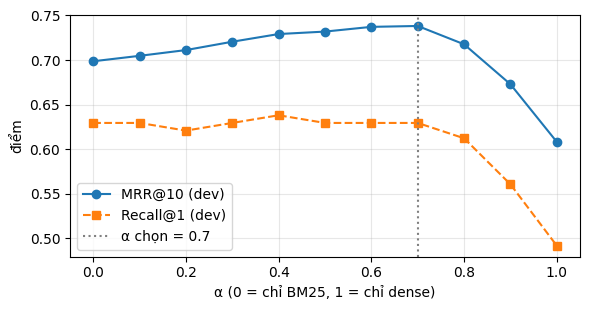


TEST clean (chỉ báo cáo):
                               recall@1  recall@3  recall@5  recall@10  mrr@10  ndcg@10
α=0 (bỏ dense = BM25)             0.727     0.841     0.894      0.970   0.804    0.844
α=0.7 (hybrid, chọn trên dev)     0.758     0.909     0.962      0.985   0.838    0.874
α=1 (bỏ BM25 = dense)             0.576     0.758     0.818      0.909   0.674    0.730

TEST noisy (chỉ báo cáo):
                               recall@1  recall@3  recall@5  recall@10  mrr@10  ndcg@10
α=0 (bỏ dense = BM25)             0.644     0.818     0.894      0.962   0.750    0.801
α=0.7 (hybrid, chọn trên dev)     0.758     0.894     0.947      0.977   0.832    0.867
α=1 (bỏ BM25 = dense)             0.545     0.712     0.795      0.909   0.649    0.711

Nhận xét: trên dev, MRR@10 của BM25 (α=0) = 0.699, của dense (α=1) = 0.608; hybrid tại α = 0.7 đạt 0.738 (+0.040 so với BM25, +0.130 so với dense).
→ Hybrid hơn cả hai tín hiệu đơn lẻ: BM25 khớp chính xác tên đơn vị/từ khóa (vd. 'Phòng Khảo 

In [23]:
import matplotlib.pyplot as plt
print("Bảng quét α trên DEV (chọn α theo MRR@10):")
print(sweep_dev[["recall@1", "recall@3", "mrr@10", "ndcg@10"]].round(3))

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(sweep_dev.index, sweep_dev["mrr@10"], "o-", label="MRR@10 (dev)")
ax.plot(sweep_dev.index, sweep_dev["recall@1"], "s--", label="Recall@1 (dev)")
ax.axvline(alpha_best, color="gray", ls=":", label=f"α chọn = {alpha_best}")
ax.set_xlabel("α (0 = chỉ BM25, 1 = chỉ dense)"); ax.set_ylabel("điểm"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

abl_test = pd.DataFrame({
    "α=0 (bỏ dense = BM25)": ret["bm25_clean"], f"α={alpha_best} (hybrid, chọn trên dev)": ret["hybrid_clean"], "α=1 (bỏ BM25 = dense)": ret["dense_clean"]}).T
abl_test_noisy = pd.DataFrame({
    "α=0 (bỏ dense = BM25)": ret["bm25_noisy"], f"α={alpha_best} (hybrid, chọn trên dev)": ret["hybrid_noisy"], "α=1 (bỏ BM25 = dense)": ret["dense_noisy"]}).T
print("\nTEST clean (chỉ báo cáo):"); print(abl_test.round(3))
print("\nTEST noisy (chỉ báo cáo):"); print(abl_test_noisy.round(3))

# nhận xét tự sinh từ số liệu
m0, m1, mb = (sweep_dev.loc[a, "mrr@10"] for a in (0.0, 1.0, alpha_best))
print(f"\nNhận xét: trên dev, MRR@10 của BM25 (α=0) = {m0:.3f}, của dense (α=1) = {m1:.3f}; hybrid tại α = {alpha_best} đạt {mb:.3f} "
      f"({mb - m0:+.3f} so với BM25, {mb - m1:+.3f} so với dense).")
if mb > max(m0, m1) + 1e-9:
    print("→ Hybrid hơn cả hai tín hiệu đơn lẻ: BM25 khớp chính xác tên đơn vị/từ khóa (vd. 'Phòng Khảo thí'), dense bắt được cách diễn đạt đời thường (alias) mà BM25 không khớp từ; min-max đưa hai thang điểm về cùng khoảng [0,1] nên cộng có nghĩa.")
elif mb >= max(m0, m1) - 1e-9:
    print("→ Hybrid chỉ ngang tín hiệu mạnh nhất trên dev: tín hiệu còn lại gần như không bổ sung thêm thông tin.")
test_gain = ret["hybrid_clean"]["mrr@10"] - max(ret["bm25_clean"]["mrr@10"], ret["dense_clean"]["mrr@10"])
print(f"→ Trên test sạch, hybrid so với tín hiệu tốt nhất đơn lẻ: {test_gain:+.3f} MRR@10; α chọn trên dev có chuyển sang test hay không phụ thuộc vào dev chỉ có {len(dev)} câu / {dev.item_id.nunique()} mục.")
ablation_res = {"id": card["ablation"], "desc": card["ablation_desc"], "alpha_best": alpha_best,
                "dev_sweep": {str(a): {"recall@1": sweep_dev.loc[a, "recall@1"], "mrr@10": sweep_dev.loc[a, "mrr@10"]} for a in ALPHAS},
                "test_clean": {"alpha0_bm25": ret["bm25_clean"], "alpha_best": ret["hybrid_clean"], "alpha1_dense": ret["dense_clean"]}}

### F2. Confusion matrix cho `topic_pair` và phân loại nguyên nhân lỗi
Dùng bộ phân loại tốt hơn (theo macro-F1 trên test sạch) giữa B1 và C3.

Bộ phân loại dùng để phân tích: tfidf_lr | topic_pair = ['thi_diem', 'thu_vien_cntt']

Confusion matrix (clean) – hàng: nhãn thật, cột: dự đoán ("khác" = chủ đề ngoài cặp):
                     đoán: thi_diem  đoán: thu_vien_cntt  đoán: khác
thật: thi_diem                   48                    0           0
thật: thu_vien_cntt              19                   24           5

Confusion matrix (noisy) – hàng: nhãn thật, cột: dự đoán ("khác" = chủ đề ngoài cặp):
                     đoán: thi_diem  đoán: thu_vien_cntt  đoán: khác
thật: thi_diem                   48                    0           0
thật: thu_vien_cntt              16                   24           8


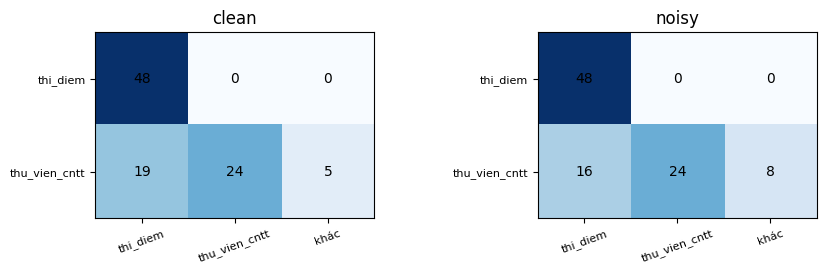


Tổng số câu sai thuộc topic_pair: 48 (clean 24, noisy 24)
Phân loại nguyên nhân (luật tự động):
nguyên nhân
từ khóa gây nhầm    32
thiếu ngữ cảnh      16
Name: count, dtype: int64

Các câu sai tiêu biểu:
  tập     qid                                                                câu hỏi          thật     đoán      nguyên nhân                                   chi tiết  mục
clean Q066-08 Cho hỏi, quên mật khẩu không đăng nhập được thì đơn vị nào giải quyết? thu_vien_cntt thi_diem   thiếu ngữ cảnh không có từ khóa đặc trưng cho chủ đề đúng Q066
clean Q066-01              Muốn cấp lại mật khẩu cổng thông tin thì thực hiện ở đâu? thu_vien_cntt thi_diem từ khóa gây nhầm                  'lại' nghiêng về thi_diem Q066


In [24]:
pair = card["topic_pair"]
best_name = "emb_lr" if res_emb["clean"]["macro_f1"] >= res["clean"]["macro_f1"] else "tfidf_lr"
pred_best = pred_emb if best_name == "emb_lr" else pred_tfidf
print("Bộ phân loại dùng để phân tích:", best_name, "| topic_pair =", pair)

labels3 = [pair[0], pair[1], "khác"]
def pair_confusion(y_true, y_pred):
    y_true, y_pred = pd.Series(np.asarray(y_true)), pd.Series(np.asarray(y_pred))
    m = y_true.isin(pair)
    yp = y_pred[m].where(y_pred[m].isin(pair), "khác")
    cm = confusion_matrix(y_true[m], yp, labels=labels3)[:2]
    return pd.DataFrame(cm, index=[f"thật: {p}" for p in pair], columns=[f"đoán: {p}" for p in labels3])

cms = {"clean": pair_confusion(te.topic, pred_best["clean"]), "noisy": pair_confusion(te_noisy.topic, pred_best["noisy"])}
fig, axes = plt.subplots(1, 2, figsize=(9, 2.8))
for ax, (name, cm) in zip(axes, cms.items()):
    print(f"\nConfusion matrix ({name}) – hàng: nhãn thật, cột: dự đoán (\"khác\" = chủ đề ngoài cặp):"); print(cm)
    ax.imshow(cm.values, cmap="Blues"); ax.set_title(name)
    ax.set_xticks(range(3)); ax.set_xticklabels(labels3, rotation=20, fontsize=8); ax.set_yticks(range(2)); ax.set_yticklabels(pair, fontsize=8)
    for (i, j), v in np.ndenumerate(cm.values): ax.text(j, i, v, ha="center", va="center")
plt.tight_layout(); plt.show()

rows = []
for name, df in [("clean", te), ("noisy", te_noisy)]:
    y, pr = df.topic.values, pred_best[name]
    for i in np.where(np.isin(y, pair) & (pr != y))[0]:
        clean_ok = name == "noisy" and pred_best["clean"][i] == y[i]
        cause, detail = diagnose_error(df.text.iloc[i], y[i], pr[i], noisy=(name == "noisy"), clean_ok=clean_ok)
        rows.append({"tập": name, "qid": df.qid.iloc[i], "câu hỏi": df.text.iloc[i], "thật": y[i], "đoán": pr[i], "nguyên nhân": cause, "chi tiết": detail})
err = pd.DataFrame(rows)
print(f"\nTổng số câu sai thuộc topic_pair: {len(err)} (clean {sum(err['tập'] == 'clean')}, noisy {sum(err['tập'] == 'noisy')})")
print("Phân loại nguyên nhân (luật tự động):"); print(err["nguyên nhân"].value_counts())
err["mục"] = err.qid.str.split("-").str[0]
show = err.drop_duplicates(["nguyên nhân", "mục"]).groupby("nguyên nhân").head(4).sort_values("nguyên nhân")   # đa dạng: mỗi (nguyên nhân, mục) 1 câu
print("\nCác câu sai tiêu biểu:"); print(show.to_string(index=False))
err.to_csv("error_analysis.csv", index=False, encoding="utf-8-sig")

In [25]:
# F2 (bổ sung): lỗi của bộ phân loại embedding (C3) trên topic_pair – đa dạng hơn, có thể có lỗi do nhiễu
rows2 = []
for name, df in [("clean", te), ("noisy", te_noisy)]:
    y, pr = df.topic.values, pred_emb[name]
    for i in np.where(np.isin(y, pair) & (pr != y))[0]:
        clean_ok = name == "noisy" and pred_emb["clean"][i] == y[i]          # đúng khi chưa nhiễu, sai sau nhiễu
        cause, detail = diagnose_error(df.text.iloc[i], y[i], pr[i], noisy=(name == "noisy"), clean_ok=clean_ok)
        rows2.append({"tập": name, "qid": df.qid.iloc[i], "mục": df.qid.iloc[i].split("-")[0], "câu hỏi": df.text.iloc[i],
                      "thật": y[i], "đoán": pr[i], "nguyên nhân": cause, "chi tiết": detail})
err_emb = pd.DataFrame(rows2)
print(f"Bộ phân loại embedding: {len(err_emb)} câu sai thuộc topic_pair, thuộc {err_emb['mục'].nunique() if len(err_emb) else 0} mục khác nhau")
if len(err_emb):
    print(err_emb.groupby(["tập", "nguyên nhân"]).size().unstack(fill_value=0))
    print(pd.concat([err_emb.drop_duplicates(["nguyên nhân", "mục"]).groupby("nguyên nhân").head(4)]).sort_values("nguyên nhân").to_string(index=False))
    err_emb.to_csv("error_analysis_embedding.csv", index=False, encoding="utf-8-sig")


Bộ phân loại embedding: 32 câu sai thuộc topic_pair, thuộc 3 mục khác nhau
nguyên nhân  mơ hồ  nhiễu  thiếu ngữ cảnh  từ khóa gây nhầm
tập                                                        
clean            4      0               6                 4
noisy            4      4               6                 4
  tập     qid  mục                                                                câu hỏi          thật       đoán      nguyên nhân                                       chi tiết
clean Q066-05 Q066                Em quên mật khẩu không đăng nhập được, thì làm ở đâu ạ? thu_vien_cntt  ky_tuc_xa            mơ hồ                 từ ủng hộ chủ đề đúng: ['làm']
noisy Q031-03 Q031                     Nơi tiếp nhận document phúc khảo bài thi là đâu ạ?      thi_diem tot_nghiep            nhiễu từ ngoài từ vựng: ['document', 'phúc', 'khảo']
noisy Q032-16 Q032 Cho hỏi, bị ốm không đi thi được thì thời gian submit document ra sao?      thi_diem       ctsv            nhiễu từ ngoài từ vựng

**Cách đọc bảng lỗi.** *Nhiễu*: câu đúng khi còn tiếng Việt nhưng sai sau khi từ khóa bị thay bằng tiếng Anh. *Thiếu ngữ cảnh*: câu chỉ hỏi chung (*"mất bao nhiêu tiền?"*, *"làm ở đâu?"*) nên không có từ khóa nào chỉ ra chủ đề. *Từ khóa gây nhầm*: có từ thuộc chủ đề kia (vd. *"thẻ", "mật khẩu", "bảng điểm"* xuất hiện ở cả thư viện/CNTT lẫn thi cử/công tác sinh viên). *Mơ hồ*: câu có thể hợp lý với cả hai chủ đề (vd. cấp bảng điểm do Phòng Đào tạo ↔ giấy tờ do Phòng Công tác sinh viên). Các nhãn nguyên nhân do luật gợi ý – khi vấn đáp em cần đọc lại từng câu và tự giải thích bằng lời của mình.

### F3. Tự viết 10 câu hỏi mới cho mỗi chủ đề trong `topic_pair` → `own_queries.csv`, đo Recall@3
20 câu hỏi mới (diễn đạt tự nhiên, không sao chép mẫu có sẵn; soạn có hỗ trợ AI – xem nhật ký trong `report.md`), mỗi câu gắn với đúng đoạn quy định (`gold_passage_id`). Code tự kiểm tra: không trùng câu nào trong dữ liệu, `gold_passage_id` đúng chủ đề.

In [26]:
OWN_QUERIES = [
    # ---- thi_diem (P031–P040) ----
    ("Điểm cuối kỳ môn Giải tích lệch xa so với mình tự ước lượng, có cách nào xin xem xét lại bài làm không?", "thi_diem", "P031"),
    ("Hôm thi bị sốt cao phải vào bệnh viện, mình có xin dời sang lần thi khác được không?",                   "thi_diem", "P032"),
    ("Trượt môn Xác suất thống kê thì ghi danh thi lần hai trong khoảng thời gian nào?",                      "thi_diem", "P033"),
    ("Cần bản in toàn bộ điểm các học kỳ để nộp hồ sơ xin việc thì bao lâu sẽ nhận được?",                    "thi_diem", "P034"),
    ("Mình xin bảng điểm bằng tiếng Anh để nộp hồ sơ du học thì mỗi bản tính phí bao nhiêu?",                 "thi_diem", "P035"),
    ("Điểm kiểm tra giữa kỳ bị chấm thiếu ý, mình phản ánh với ai và trong bao nhiêu ngày?",                  "thi_diem", "P036"),
    ("Khi nào em đủ điều kiện ghi danh kỳ thi chuẩn ngoại ngữ để ra trường?",                                  "thi_diem", "P037"),
    ("Làm mất giấy báo dự thi sát ngày thi thì xin cấp lại ở đâu?",                                            "thi_diem", "P038"),
    ("Em đang thực tập xa trường, muốn thi ở địa điểm khác với lịch của khoa thì phải báo trước bao lâu?",     "thi_diem", "P039"),
    ("Xem thời gian các buổi thi cuối kỳ ở trang nào của trường?",                                             "thi_diem", "P040"),
    # ---- thu_vien_cntt (P061–P070) ----
    ("Sinh viên mới nhập học muốn có thẻ để vào đọc sách ở thư viện thì cần làm gì?",                          "thu_vien_cntt", "P061"),
    ("Mình được giữ cuốn giáo trình ở nhà tối đa mấy ngày?",                                                    "thu_vien_cntt", "P062"),
    ("Sách sắp đến hạn trả mà mình chưa đọc xong, xin mượn thêm hạn vào lúc nào thì được?",                    "thu_vien_cntt", "P063"),
    ("Lỡ làm thất lạc quyển sách mượn từ thư viện thì phải đền thế nào?",                                       "thu_vien_cntt", "P064"),
    ("Nhóm 5 người tụi mình muốn có phòng riêng để làm đồ án ở thư viện, phải giữ chỗ sớm ra sao?",            "thu_vien_cntt", "P065"),
    ("Quên mật khẩu đăng nhập hệ thống của sinh viên thì liên hệ bộ phận nào để đặt lại?",                     "thu_vien_cntt", "P066"),
    ("Muốn kết nối mạng không dây trong khuôn viên trường thì đăng ký ở đâu và có tốn phí không?",             "thu_vien_cntt", "P067"),
    ("Khi nào mình sẽ có địa chỉ thư điện tử của trường sau khi nhập học?",                                    "thu_vien_cntt", "P068"),
    ("Cần cài bộ phần mềm trường đã mua bản quyền lên laptop cá nhân thì nộp yêu cầu như thế nào?",            "thu_vien_cntt", "P069"),
    ("Ở nhà vẫn muốn đọc tạp chí khoa học của thư viện điện tử, có cách kết nối từ xa không?",                 "thu_vien_cntt", "P070"),
]
own = pd.DataFrame(OWN_QUERIES, columns=["text", "topic", "gold_passage_id"])
kb_topic = kb.set_index("passage_id").topic
assert len(own) == 20 and set(own.topic) == set(pair) and (own.topic.value_counts() == 10).all()
assert all(kb_topic[g] == t for t, g in zip(own.topic, own.gold_passage_id)), "gold_passage_id phải thuộc đúng chủ đề"
existing = {normalize(t) for t in pd.concat([tr.text, te.text, dev.text, rq.text, llm_eval.text, fewshot.text])}
assert not any(normalize(t) in existing for t in own.text), "có câu trùng với dữ liệu sẵn có"
own.to_csv("own_queries.csv", index=False, encoding="utf-8-sig")
print("Đã lưu own_queries.csv:", own.shape)

# đo Recall@3 của hệ thống (hybrid với α chốt từ dev) và so với BM25 / dense
D_own, B_own = dense_matrix(own.text), bm25_matrix(own.text)
own_systems = {"bm25": B_own, "dense": D_own, "hybrid": hybrid_scores(D_own, B_own, alpha_best)}
own_metrics = {name: eval_matrix(S, own) for name, S in own_systems.items()}
print(pd.DataFrame(own_metrics).T[["recall@1", "recall@3", "mrr@10"]].round(3))
H_own = own_systems["hybrid"]
own_ranks = np.array([rank_of_gold(H_own[i], pid2idx[g]) for i, g in enumerate(own.gold_passage_id)])
per_topic = {t: float((own_ranks[own.topic.values == t] <= 3).mean()) for t in pair}
print("Recall@3 (hybrid) theo chủ đề:", per_topic)
miss = own.assign(hạng=own_ranks)[own_ranks > 3]
if len(miss):
    miss = miss.assign(top3=[[kb.title.values[j] for j in np.argsort(-H_own[i], kind="stable")[:3]] for i in miss.index])
    print("\nCâu không vào top-3:"); print(miss[["text", "gold_passage_id", "hạng", "top3"]].to_string(index=False))
own_res = {"n": len(own), "recall@3_hybrid": own_metrics["hybrid"]["recall@3"], "recall@3_bm25": own_metrics["bm25"]["recall@3"],
           "recall@3_dense": own_metrics["dense"]["recall@3"], "recall@3_by_topic": per_topic}

Đã lưu own_queries.csv: (20, 3)
        recall@1  recall@3  mrr@10
bm25         0.6      0.80   0.698
dense        0.5      0.75   0.649
hybrid       0.7      0.90   0.806
Recall@3 (hybrid) theo chủ đề: {'thi_diem': 0.8, 'thu_vien_cntt': 1.0}

Câu không vào top-3:
                                                                                              text gold_passage_id  hạng                                                 top3
Em đang thực tập xa trường, muốn thi ở địa điểm khác với lịch của khoa thì phải báo trước bao lâu?            P039     5      [Tra cứu lịch thi, Hoãn thi, Phúc khảo bài thi]
                                        Xem thời gian các buổi thi cuối kỳ ở trang nào của trường?            P040     4 [Đánh giá điểm rèn luyện, Đăng ký thi lại, Hoãn thi]


### F4. Hạn chế, rủi ro và cải tiến
1. **Hạn chế dữ liệu:** KB chỉ có 80 đoạn *giả lập* theo hai mẫu câu cố định, câu hỏi sinh từ khuôn mẫu; kết quả không phản ánh quy chế thật và khó khái quát sang văn bản dài, tự do.
2. **Hạn chế đánh giá:** mỗi truy vấn chỉ có đúng một đoạn đúng, `retr_test` chỉ 22 mục và dev 58 mục nên α, τ chọn trên dev có phương sai lớn; chỉ thử một kiểu nhiễu (`code_mix`).
3. **Hạn chế mô hình:** LLM 1.5B tham số có thể sai chính tả/đơn vị; RAG trích xuất dựa vào regex nên vỡ khi định dạng đoạn quy định thay đổi.
4. **Rủi ro ảo giác (hallucination):** nếu truy hồi sai, hệ thống vẫn trả lời *tự tin* bằng đơn vị/lệ phí của quy định khác (đúng kiểu cặp *rejected* trong `preference_pairs.jsonl`); ngưỡng τ chỉ chặn được câu hoàn toàn ngoài lề, còn câu *near_topic* vẫn lọt.
5. **Rủi ro quyền riêng tư:** câu hỏi sinh viên có thể chứa MSSV, hoàn cảnh cá nhân (học bổng, trợ cấp); cần ẩn danh/không lưu nhật ký thô và không gửi sang dịch vụ LLM bên ngoài khi chưa che thông tin.
6. **Rủi ro thiên lệch:** dữ liệu nghiêng về giọng văn Bắc/miền nam "đời thường" tạo sẵn; sinh viên dùng teencode, không dấu hoặc phương ngữ khác có thể bị phục vụ kém hơn (nhiễu `code_mix` đã cho thấy hiệu năng giảm).
7. **Cải tiến sẽ làm tiếp:** (i) thêm cross-encoder/reranker và fine-tune embedding bằng cặp câu hỏi–đoạn đúng (hard negative cùng chủ đề); (ii) huấn luyện bộ phát hiện OOD và đo trên tập `near_topic` lớn hơn; (iii) dùng DPO với cặp *trung thành/ảo giác* để giảm bịa; (iv) tăng cường dữ liệu bằng nhiều kiểu nhiễu (không dấu, teencode, lỗi gõ) khi huấn luyện.

## Kết quả nộp: `results.json`, `report.md`, kiểm tra checklist

In [27]:
def save_results(results: dict, path="results.json"):
    results = {"mssv": card["mssv"], "check_code": card["check_code"], **results}
    json.dump(results, open(path, "w", encoding="utf-8"), ensure_ascii=False, indent=2, default=float)
    print("Đã lưu", path)

def to_py(o):                                    # numpy -> kiểu Python thuần để JSON đẹp (int vẫn là int)
    if isinstance(o, dict):  return {str(k): to_py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_py(v) for v in o]
    if isinstance(o, np.integer):    return int(o)
    if isinstance(o, np.floating):   return float(o)
    if isinstance(o, np.bool_):      return bool(o)
    return o

clf_res = {"tfidf_lr": res, "emb_lr": res_emb, "lora": lora_info, "best_for_error_analysis": best_name}
retrieval_res = {**{k: ret[k] for k in ("bm25_clean", "bm25_noisy", "dense_clean", "dense_noisy")},
                 "hybrid": {"clean": ret["hybrid_clean"], "noisy": ret["hybrid_noisy"]}, "alpha_best": alpha_best}
toy_res = {"ranking": toy, "dpo": {"margin_h": h_margin, "loss": loss_dpo, "beta": dpo_card["beta"]}, "lora_params": lora_total,
           "lora_params_per_matrix": lora_trainable(1, HIDDEN, LORA_R, 1), "full_matrix_params": HIDDEN ** 2}
results = {"clf": clf_res, "retrieval": retrieval_res, "prompting": prompt_res,
           "rag": {**rag_res, "llm_rag": llm_rag_res}, "toy": toy_res, "ablation": ablation_res,
           "error_analysis": {"classifier": best_name, "n_errors_topic_pair": len(err), "by_cause": err["nguyên nhân"].value_counts().to_dict()},
           "own_queries": own_res, "config": {"embed_model": card["embed_model"], "clf_backbone": card["clf_backbone"], "seed": SEED, "noise": card["noise"],
                                              "topic_pair": pair, "fewshot_k": card["fewshot_k"], "rag_top_k": card["rag_top_k"]}}
save_results(to_py(results))

Đã lưu results.json


In [28]:
f3 = lambda x: "n/a" if x is None else f"{x:.3f}"
def df_to_md(df, nd=3):
    cols = [df.index.name or ""] + [str(c) for c in df.columns]
    out = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for idx, row in df.iterrows():
        out.append("| " + " | ".join([str(idx)] + [f"{v:.{nd}f}" if isinstance(v, (float, np.floating)) else str(v) for v in row]) + " |")
    return "\n".join(out)

NAMES = {"bm25": "BM25", "dense": "Dense", "hybrid": f"Hybrid (α={alpha_best})"}
cols = ["recall@1", "recall@3", "recall@5", "recall@10", "mrr@10", "ndcg@10"]
t_ret = pd.DataFrame({f"{NAMES[s]} – {c}": {k: ret[f"{s}_{c}"][k] for k in cols} for s in NAMES for c in ("clean", "noisy")}).T
t_clf = pd.DataFrame({"TF-IDF+LR": {"acc clean": res["clean"]["acc"], "F1 clean": res["clean"]["macro_f1"], "acc noisy": res["noisy"]["acc"], "F1 noisy": res["noisy"]["macro_f1"]},
                      "Embedding+LR": {"acc clean": res_emb["clean"]["acc"], "F1 clean": res_emb["clean"]["macro_f1"], "acc noisy": res_emb["noisy"]["acc"], "F1 noisy": res_emb["noisy"]["macro_f1"]}}).T
if res_lora:
    t_clf.loc["LoRA " + card["clf_backbone"]] = [res_lora["clean"]["acc"], res_lora["clean"]["macro_f1"], res_lora["noisy"]["acc"], res_lora["noisy"]["macro_f1"]]

mrr_drop = {s: ret[f"{s}_clean"]["mrr@10"] - ret[f"{s}_noisy"]["mrr@10"] for s in NAMES}
best_clean = max(NAMES, key=lambda s: ret[f"{s}_clean"]["mrr@10"])
find1 = (f"**Truy hồi.** Trên `retr_test` sạch, hệ tốt nhất là {NAMES[best_clean]} (MRR@10 = {ret[f'{best_clean}_clean']['mrr@10']:.3f}, Recall@3 = {ret[f'{best_clean}_clean']['recall@3']:.3f}). "
         f"Khi sang tập nhiễu `{card['noise']}`, MRR@10 của BM25 giảm {mrr_drop['bm25']:.3f}, dense giảm {mrr_drop['dense']:.3f}, hybrid giảm {mrr_drop['hybrid']:.3f}"
         + (" – embedding bền với nhiễu hơn so với khớp từ khóa." if mrr_drop["dense"] < mrr_drop["bm25"] else " – lần chạy này dense không bền hơn BM25."))
d_clf = {k: res_emb[k]["acc"] - res[k]["acc"] for k in ("clean", "noisy")}
find2 = (f"**Phân loại.** Tách theo mục khiến bài toán khó (TF-IDF+LR chỉ đạt acc {res['clean']['acc']:.3f} sạch / {res['noisy']['acc']:.3f} nhiễu). "
         f"Embedding đóng băng+LR đạt {res_emb['clean']['acc']:.3f} / {res_emb['noisy']['acc']:.3f} ({d_clf['clean']:+.3f} / {d_clf['noisy']:+.3f} so với TF-IDF)"
         + (f"; LoRA đạt {res_lora['clean']['acc']:.3f} / {res_lora['noisy']['acc']:.3f}." if res_lora else "."))
kind_rate = ood_view.groupby("kind").abstain.mean()
kind_note = ("câu *near_topic* khó tách hơn câu *totally_off*" if kind_rate.get("totally_off", 0) > kind_rate.get("near_topic", 0)
             else "không thấy chênh lệch rõ giữa câu *near_topic* và *totally_off*")
find3 = (f"**RAG và từ chối.** RAG trích xuất (top-{RAG_K}) đạt answer_hit_rate = {rag_res['answer_hit_rate']:.3f} (chỉ top-1: {rag_res['top1_only_hit_rate']:.3f}) trên {rag_res['n_questions']} câu; "
         f"ngưỡng τ = {tau:.3f} chốt trên dev từ chối {abstain_ood:.0%} câu ngoài phạm vi nhưng từ chối nhầm {false_abstain:.0%} câu hợp lệ ({kind_note}). "
         f"Zero-shot / {K_SHOT}-shot LLM trên 30 câu: {f3(prompt_res['zero_shot_acc'])} / {f3(prompt_res['k_shot_acc'])}.")

report = f"""# Báo cáo Lab 9 – SSA-VN (Modern NLP)
**MSSV:** {MSSV} · **Họ tên:** Nguyễn Hoàng Phúc · **Hình thức:** cá nhân · **check_code:** `{card['check_code']}` · seed {SEED} · noise `{card['noise']}` · topic_pair {pair}
**Cấu hình:** embed `{card['embed_model']}`; backbone `{card['clf_backbone']}` (LoRA r={card['lora']['r']}, α={card['lora']['alpha']}); few-shot k={K_SHOT}; rag_top_k={RAG_K}; ablation {card['ablation']}.

## 1. Bảng kết quả
**Phân loại chủ đề (test):**

{df_to_md(t_clf)}

**Truy hồi (`retr_test`):**

{df_to_md(t_ret)}

**RAG / từ chối / prompting / Phần E:** answer_hit_rate = {rag_res['answer_hit_rate']:.3f}; abstain_rate_ood = {abstain_ood:.3f}; false_abstain_rate = {false_abstain:.3f}; zero-shot = {f3(prompt_res['zero_shot_acc'])}, {K_SHOT}-shot = {f3(prompt_res['k_shot_acc'])} (mô hình `{LLM_NAME}`, greedy). LoRA q,v = {lora_total:,} tham số (1 ma trận {lora_trainable(1, HIDDEN, LORA_R, 1):,} = 1/{HIDDEN**2 // lora_trainable(1, HIDDEN, LORA_R, 1)} ma trận đầy đủ); DPO margin h = {h_margin:.2f}, loss = {loss_dpo:.2e}; toy: P@5 = {toy['P@5']:.2f}, R@5 = {toy['R@5']:.2f}, RR = {toy['RR']:.2f}, nDCG@5 = {toy['nDCG@5']:.4f}. Recall@3 trên 20 câu tự viết (hybrid) = {own_res['recall@3_hybrid']:.3f}.

## 2. Ba phát hiện chính
1. {find1}
2. {find2}
3. {find3}

## 3. Ablation {card['ablation']} – {card['ablation_desc']}
Chọn α trên dev theo MRR@10 → **α = {alpha_best}**. Bảng dev (MRR@10): {", ".join(f"α={a}: {sweep_dev.loc[a, 'mrr@10']:.3f}" for a in ALPHAS)}. Test (α=0 / chọn / α=1), MRR@10 sạch: {ret['bm25_clean']['mrr@10']:.3f} / {ret['hybrid_clean']['mrr@10']:.3f} / {ret['dense_clean']['mrr@10']:.3f}; nhiễu: {ret['bm25_noisy']['mrr@10']:.3f} / {ret['hybrid_noisy']['mrr@10']:.3f} / {ret['dense_noisy']['mrr@10']:.3f}. BM25 mạnh ở khớp từ chính xác, dense mạnh ở diễn đạt khác từ; hybrid kết hợp hai thang điểm sau min-max (chi tiết số liệu ở notebook F1).

## 4. Hạn chế, rủi ro, cải tiến
Hạn chế: dữ liệu giả lập, KB chỉ 80 đoạn theo khuôn mẫu; dev/test nhỏ nên α, τ nhiều phương sai; chỉ một kiểu nhiễu. Rủi ro: ảo giác khi truy hồi sai (vẫn trả lời tự tin, ngưỡng τ chỉ chặn câu hoàn toàn ngoài lề); quyền riêng tư (câu hỏi chứa MSSV/hoàn cảnh cá nhân); thiên lệch với teencode/không dấu/phương ngữ. Sẽ làm tiếp: reranker (cross-encoder) và fine-tune embedding bằng hard negative cùng chủ đề; bộ phát hiện OOD; DPO với cặp trung thành/ảo giác; tăng cường nhiều kiểu nhiễu.

## 5. Nhật ký sử dụng AI
- **Công cụ:** Claude (Anthropic, qua ứng dụng Claude/Cowork).
- **AI hỗ trợ:** đọc đề và các lab tham khảo (Lab 7, Lab 8); dựng khung và viết code các phần C–F trong notebook; soạn lời giải tay E1–E3 để đối chiếu; viết 20 câu hỏi `own_queries.csv`; soạn nháp báo cáo này (số liệu được sinh tự động từ notebook).
- **Phần có sẵn từ giảng viên giữ nguyên:** `normalize`, `BM25`, các hàm metric truy hồi, baseline TF-IDF+LR, `save_results`.
- **Kiểm chứng:** mọi hàm tính tay (E1–E3) được kiểm bằng `assert` và đối chiếu thư viện (scikit-learn, SciPy, peft); không chọn siêu tham số bằng tập test (α, τ chốt trên dev).
- **Trách nhiệm:** người nộp chạy lại notebook (Restart & Run All) và tự giải thích từng dòng khi vấn đáp.

## 6. Phân công
Làm cá nhân: toàn bộ Phần A–F do MSSV {MSSV} thực hiện.
"""
open("report.md", "w", encoding="utf-8").write(report)
print("Đã lưu report.md:", len(report.split()), "từ")

Đã lưu report.md: 790 từ


### Checklist tự kiểm tra (mục 10 của đề)

In [29]:
saved = json.load(open("results.json", encoding="utf-8"))
checks = {
    "check_code trong results.json trùng với thẻ": saved["check_code"] == card["check_code"] and saved["mssv"] == MSSV,
    "Không rò rỉ train/test (item_id tách rời)": set(tr.item_id).isdisjoint(te.item_id) and set(dev.item_id).isdisjoint(rq.item_id),
    "α được chọn trên dev (không dùng test)": alpha_best == ALPHAS[int(np.argmax(sweep_dev["mrr@10"].values))],
    "Ngưỡng τ chốt trên dev (không dùng ood/test)": abs(tau - np.percentile(D_dev.max(axis=1), 5)) < 1e-12,
    "RAG đo trên ≥ 60 câu của retr_test": rag_res["n_questions"] >= 60,
    "E1–E3: code khớp lời giải tay (LoRA 294.912 | h = 8,4 | nDCG@5 ≈ 0,6934)": lora_total == lora_trainable(LAYERS, HIDDEN, LORA_R) and abs(h_margin - 8.4) < 1e-9 and abs(toy["nDCG@5"] - 0.6934) < 5e-5,
    "own_queries.csv: 10 câu/chủ đề × 2 chủ đề": len(pd.read_csv("own_queries.csv")) == 20,
    "results.json có đủ các mục": all(k in saved for k in ("clf", "retrieval", "prompting", "rag", "toy", "ablation", "own_queries")),
    "report.md đã tạo": os.path.exists("report.md"),
}
for k, v in checks.items():
    print("✔" if v else "✘", k)
assert all(checks.values())
print("\nCòn lại (làm tay, ngoài notebook): chụp màn hình thẻ cá nhân; chụp ảnh lời giải tay E1–E3; tự đọc lại 3 câu sai ở D1/F2 để giải thích khi vấn đáp.")

✔ check_code trong results.json trùng với thẻ
✔ Không rò rỉ train/test (item_id tách rời)
✔ α được chọn trên dev (không dùng test)
✔ Ngưỡng τ chốt trên dev (không dùng ood/test)
✔ RAG đo trên ≥ 60 câu của retr_test
✔ E1–E3: code khớp lời giải tay (LoRA 294.912 | h = 8,4 | nDCG@5 ≈ 0,6934)
✔ own_queries.csv: 10 câu/chủ đề × 2 chủ đề
✔ results.json có đủ các mục
✔ report.md đã tạo

Còn lại (làm tay, ngoài notebook): chụp màn hình thẻ cá nhân; chụp ảnh lời giải tay E1–E3; tự đọc lại 3 câu sai ở D1/F2 để giải thích khi vấn đáp.
